# Week 5 — Cross-architecture comparison and robustness (Q3)

**Question.** **Q3**: does the fluxonium's flux sweet spot buy more coherence robustness than the
transmon's charge insensitivity, and at what design cost?

**Method.** Every number here is computed from `src/coherence.py` — the same pipeline validated in
`01_validation.ipynb` and used for the sweeps in `02_transmon_sweep.ipynb` and
`03_fluxonium_sweep.ipynb`. No physics is redefined in this notebook. The operating points are
inherited from those notebooks and asserted against them in §0.

**Status.** All model-based estimates. §3 shows that the answer to Q3 depends on the metric chosen
by more than two orders of magnitude, so this notebook's output is *a set of metrics with their
uncertainties*, not a single winner.

---

### What a reader needs to know before quoting any number

1. **The previous version of this notebook answered Q3 with a comparison that was rigged on both
   sides.** It compared a "transmon" at $E_J{=}50$, $E_C{=}1.0$ GHz — which is an $18.9$ GHz qubit,
   three times above the $3$–$6$ GHz design range transmons actually occupy (Krantz 2019 §II A) and
   with $|\alpha| = 1$ GHz against the usual 100–300 MHz — held at its **worst-case** charge bias,
   against a fluxonium at $E_J{=}15$, $E_L{=}0.2$ GHz held at its **best** bias. That fluxonium
   sits at $f_{01} = 75$ MHz with $\bar n_{\rm th} = 3.7$; `03_fluxonium_sweep.ipynb` Appendix A
   retired it explicitly as "not a design point — thermally scrambled, below any published device."
   The resulting headline (median $216\times$, 100% win rate) is superseded. §1 replaces both
   operating points and Appendix A records the correction.

2. **The old fluxonium physics was first-order only.** This notebook previously defined
   `fluxonium_T2` inline without the second-order $1/f$ flux dephasing channel that notebook 03
   added (Nguyen 2019 Eq. A3, published numbering). At the sweet spot that channel carries only 0.63% of the rate
   budget, so the change is small *here* — but the inline duplicate could drift from `src/`
   silently, and it did. All physics is now imported.

3. **There is no single answer to Q3.** §3 computes three defensible comparisons — raw $T_2$,
   frequency-matched $T_2$, and gate count — and they disagree by a factor of $\sim 500$. Quoting
   one without naming the metric is not a defensible comparison.

4. **The gate-count metric is this project's own heuristic, and the pulse-length bound inside it
   is unsettled.** Krantz 2019 states that anharmonicity bounds how short a pulse can be, but does
   *not* write $N = T_2|\alpha|$. Worse, $|\alpha|$ is not the only bound: a drive cannot be much
   shorter than one period of the transition it drives, and for this fluxonium
   $|\alpha| = 8.7$ GHz is 24× its own $0.363$ GHz transition. §3 computes three bounds and §4
   carries them all through the Monte Carlo. **The fluxonium's gate-count advantage is $524\times$,
   $22\times$ or $1.34\times$ depending on which is used** — a spread comparable to the entire
   spread across metrics 1–3.

*Corrections relative to earlier versions are in Appendix A; references with DOIs in Appendix B.*

In [1]:
# --- project bootstrap: run from anywhere, keeps data/ and figures/ paths working ---
import os, sys
from pathlib import Path
_here = Path.cwd()
if _here.name == "notebooks":          # notebook lives in notebooks/, project root is one level up
    os.chdir(_here.parent)
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))  # makes `from coherence import ...` available
os.makedirs("data", exist_ok=True); os.makedirs("figures", exist_ok=True)
print("project root:", ROOT.name)          # name only; the absolute path is machine-specific

project root: quantum-coherence-sweet-spots-transmon-fluxonium


## 0. Setup, provenance, and the chain of custody to notebooks 02 and 03

This notebook consumes results from two upstream notebooks and must not silently drift from them.
Three things are asserted before any analysis runs.

**Physics identity.** `src/coherence.py` must reproduce the nominal points recorded by notebooks 01
and 02. The previous version of this notebook carried its own inline `transmon_T2` and
`fluxonium_T2`, which is precisely how the second-order flux channel came to be missing here after
it was added upstream. Nothing is redefined below.

**Upstream artefacts.** `data/q3_comparison.json` and the fluxonium CSVs are written by notebook 03.
Their provenance block records the git revision and the noise amplitudes in force when they were
produced; if those disagree with this run's, the analysis is comparing incompatible artefacts.

**Complete provenance.** The full scqubits `NOISE_PARAMS` dictionary is captured, not just the three
amplitudes this project passes explicitly — $T$, $x_{qp}$, $\Delta$, $t_{\rm exp}$ and
$\omega_{\rm low}$ all enter these results.

In [2]:
import json, platform
from datetime import datetime

import numpy as np
import pandas as pd
import scqubits as scq
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize, minimize_scalar

from qubits import (make_transmon, make_fluxonium, qubit_frequency, anharmonicity,
                    TRANSMON_DEFAULTS, FLUXONIUM_DEFAULTS)
from coherence import (transmon_coherence, fluxonium_coherence, n_thermal,
                       git_revision, noise_param_snapshot, reset_channel_failures,
                       CHANNEL_FAILURES, DEFAULTS)
import plotting as pl

scq.settings.T1_DEFAULT_WARNING = False

NOISE_PARAMS_SNAPSHOT = noise_param_snapshot()

PROVENANCE = {
    "date": datetime.now().isoformat(timespec="seconds"),
    "git_revision": git_revision(),
    "python": platform.python_version(), "numpy": np.__version__,
    "pandas": pd.__version__, "scqubits": scq.__version__,
    "platform": platform.platform(),
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_flux", "A_cc")},
    "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
    "units": "frequencies GHz; coherence times microseconds",
}
for k, v in PROVENANCE.items():
    if k != "scqubits_noise_params":
        print(f"{k:22s} {v}")

# ---- chain of custody: physics identity -------------------------------------
VALIDATED_TRANSMON_T2 = 54.35208346332045     # 01/02, nominal EJ=15, EC=0.3, ng=0
VALIDATED_FLUXONIUM_T2 = 1136.8688060132743   # 01 section 6, first-order-only pipeline

_tm_nom = transmon_coherence(**TRANSMON_DEFAULTS)
_fx_nom = fluxonium_coherence(**FLUXONIUM_DEFAULTS, second_order_flux=False)
for label, got, want in [("transmon nominal", _tm_nom["T2_us"], VALIDATED_TRANSMON_T2),
                         ("fluxonium nominal (1st order only)", _fx_nom["T2_us"],
                          VALIDATED_FLUXONIUM_T2)]:
    rel = abs(got - want) / want
    print(f"\n{label}: T2 = {got:.10f} us vs record {want:.10f} us  (rel {rel:.1e})")
    assert rel < 1e-9, f"src/coherence.py no longer reproduces the validated {label}"
print("\n-> physics identity verified against notebooks 01 and 02")

# ---- chain of custody: upstream artefacts -----------------------------------
Q3_UP = json.loads(Path("data/q3_comparison.json").read_text())
FX_META = json.loads(Path("data/fluxonium_metadata.json").read_text())
TM_META = json.loads(Path("data/transmon_sweep_metadata.json").read_text())

print(f"\nupstream artefacts:")
print(f"   data/q3_comparison.json        (notebook 03 section 9)")
print(f"   data/fluxonium_metadata.json   written {FX_META['provenance']['date']}, "
      f"git {FX_META['provenance']['git_revision']}")
print(f"   data/transmon_sweep_metadata.json written {TM_META['provenance']['date']}")

for name, meta in [("fluxonium", FX_META), ("transmon", TM_META)]:
    up = meta["noise_amplitudes"]
    for k, v in up.items():
        assert abs(DEFAULTS[k] - v) < 1e-30, (
            f"{name} artefacts were produced with {k}={v}, this run uses {DEFAULTS[k]}")
print("   noise amplitudes in the upstream metadata match this run -> artefacts are compatible")

date                   2026-09-07T23:30:04
git_revision           81dc9c6-dirty
python                 3.11.15
numpy                  2.2.6
pandas                 3.0.3
scqubits               4.3.1
platform               macOS-15.0-arm64-arm-64bit
noise_amplitudes       {'Q_cap': 1000000.0, 'A_ng': 0.0001, 'A_flux': 1e-06, 'A_cc': 1e-07}
units                  frequencies GHz; coherence times microseconds

transmon nominal: T2 = 54.3520834633 us vs record 54.3520834633 us  (rel 0.0e+00)

fluxonium nominal (1st order only): T2 = 1136.8688060133 us vs record 1136.8688060133 us  (rel 0.0e+00)

-> physics identity verified against notebooks 01 and 02

upstream artefacts:
   data/q3_comparison.json        (notebook 03 section 9)
   data/fluxonium_metadata.json   written 2026-09-07T23:28:03, git 81dc9c6-dirty
   data/transmon_sweep_metadata.json written 2026-09-07T23:27:54
   noise amplitudes in the upstream metadata match this run -> artefacts are compatible


## 1. The two operating points that decided the old answer

Q3 is a comparison, and a comparison is only as good as the two things being compared. The previous
version of this notebook chose both badly, and in the same direction — each choice inflated the
fluxonium's apparent advantage. Both are replaced here, and the replacements are inherited from the
upstream notebooks rather than invented.

**Transmon: $E_J{=}50$, $E_C{=}1.0$ GHz is not a transmon anyone builds.** Its $E_J/E_C = 50$ is in
range, but $\sqrt{8E_JE_C} - E_C$ puts it at $18.9$ GHz. Krantz 2019 §II A states the design target
plainly: *"$\alpha = -E_C$ is usually designed to be $100-300$ MHz, as required to maintain a
desirable qubit frequency $\omega_q = (\sqrt{8E_JE_C} - E_C)/\hbar = 3-6$ GHz, while keeping an
energy ratio sufficiently large ($E_J/E_C \geq 50$) to suppress charge sensitivity."* The old point
misses the frequency window by 3× and the anharmonicity window by 3–10×. Because
$T_1^{\rm diel}$ falls with frequency, an 18.9 GHz transmon is heavily penalised on $T_2$ for no
physical reason. **Replacement:** $E_J{=}13.0$, $E_C{=}0.26$ GHz — notebook 02 §6.1's operating
point, $E_J/E_C = 50$, $f_{01} = 4.92$ GHz, $|\alpha| = 299$ MHz. Inside Krantz's envelope on every
axis.

**Fluxonium: $E_J{=}15$, $E_L{=}0.2$ GHz is a point notebook 03 already retired.** It was the raw
$T_2$ maximum of the $(E_J, E_L)$ grid, but it sits on *two* grid edges at $f_{01} = 75$ MHz with
$\bar n_{\rm th} = 3.7$ — thermally scrambled, and 2.3× below the lowest published device (Nguyen
2019, 0.17 GHz). Notebook 03 Appendix A row 2 records it as "not a design point". **Replacement:**
the Manucharyan 2009 nominal design $E_J{=}8.9$, $E_C{=}2.5$, $E_L{=}0.5$ GHz, which is the design
notebook 01 validated the spectrum against, plus the best design *within the published frequency
band* as a second reference.

**Bias asymmetry.** The old comparison additionally held the transmon at its worst charge bias
($n_g = 0.25$) while holding the fluxonium at its best flux bias ($\Phi/\Phi_0 = 0.5$). Below, both
are evaluated at their own sweet spot, and §2 shows the choice is almost immaterial for the
transmon (1.006× across the entire period) while being decisive for the fluxonium — which is itself
the answer to Q3 and should be *reported*, not silently baked into the operating points.

In [3]:
# ---------------- operating points, inherited and asserted -------------------
TM_OP = dict(EJ=13.0, EC=0.26, ncut=30)                 # notebook 02 section 6.1
FX_OP = dict(FLUXONIUM_DEFAULTS)                        # Manucharyan 2009 nominal

TM_OLD = dict(EJ=50.0, EC=1.0, ncut=30)                 # superseded
FX_OLD = dict(EJ=15.0, EC=2.5, EL=0.2, flux=0.5, cutoff=110)   # superseded

reset_channel_failures()
tm_op = transmon_coherence(**TM_OP, ng=0.0)
fx_op = fluxonium_coherence(**FX_OP)
tm_old = transmon_coherence(**TM_OLD, ng=0.0)
fx_old = fluxonium_coherence(**FX_OLD)
fx_old_1st = fluxonium_coherence(**FX_OLD, second_order_flux=False)

assert abs(tm_op["freq_GHz"] - 4.92) < 0.02, "transmon operating point drifted from notebook 02"
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

alpha_tm = anharmonicity(make_transmon(EJ=TM_OP["EJ"], EC=TM_OP["EC"], ng=0.0, ncut=30))
alpha_fx = anharmonicity(make_fluxonium(**FX_OP))
alpha_tm_old = anharmonicity(make_transmon(EJ=TM_OLD["EJ"], EC=TM_OLD["EC"], ng=0.0, ncut=30))

rows = [
    dict(role="transmon (this notebook)", design="EJ=13.0, EC=0.26", EJ_EC=TM_OP["EJ"]/TM_OP["EC"],
         f01_GHz=tm_op["freq_GHz"], alpha_MHz=1e3*abs(alpha_tm), T2_us=tm_op["T2_us"],
         n_thermal=n_thermal(tm_op["freq_GHz"])),
    dict(role="transmon (SUPERSEDED)", design="EJ=50.0, EC=1.00", EJ_EC=TM_OLD["EJ"]/TM_OLD["EC"],
         f01_GHz=tm_old["freq_GHz"], alpha_MHz=1e3*abs(alpha_tm_old), T2_us=tm_old["T2_us"],
         n_thermal=n_thermal(tm_old["freq_GHz"])),
    dict(role="fluxonium (this notebook)", design="EJ=8.9, EL=0.5", EJ_EC=FX_OP["EJ"]/FX_OP["EC"],
         f01_GHz=fx_op["freq_GHz"], alpha_MHz=1e3*abs(alpha_fx), T2_us=fx_op["T2_us"],
         n_thermal=n_thermal(fx_op["freq_GHz"])),
    dict(role="fluxonium (SUPERSEDED)", design="EJ=15.0, EL=0.2", EJ_EC=FX_OLD["EJ"]/FX_OLD["EC"],
         f01_GHz=fx_old["freq_GHz"], alpha_MHz=np.nan, T2_us=fx_old["T2_us"],
         n_thermal=n_thermal(fx_old["freq_GHz"])),
]
ops = pd.DataFrame(rows)
display(ops.style.format({"EJ_EC": "{:.0f}", "f01_GHz": "{:.3f}", "alpha_MHz": "{:.0f}",
                          "T2_us": "{:.1f}", "n_thermal": "{:.2e}"}))

print("KRANTZ 2019 SS II A DESIGN ENVELOPE:  f01 = 3-6 GHz,  |alpha| = 100-300 MHz,  EJ/EC >= 50")
for lab, f, a, ratio in [("this notebook", tm_op["freq_GHz"], 1e3*abs(alpha_tm), TM_OP["EJ"]/TM_OP["EC"]),
                         ("superseded   ", tm_old["freq_GHz"], 1e3*abs(alpha_tm_old),
                          TM_OLD["EJ"]/TM_OLD["EC"])]:
    ok_f = 3.0 <= f <= 6.0
    ok_a = 100 <= a <= 300
    print(f"   {lab}: f01 = {f:5.2f} GHz [{'IN' if ok_f else 'OUT OF'} range]   "
          f"|alpha| = {a:6.0f} MHz [{'IN' if ok_a else 'OUT OF'} range]   EJ/EC = {ratio:.0f}")

print(f"\nThe superseded transmon is penalised {tm_op['T2_us']/tm_old['T2_us']:.1f}x on T2 purely by")
print(f"sitting at {tm_old['freq_GHz']:.1f} GHz instead of {tm_op['freq_GHz']:.1f} GHz:")
print(f"   T2 = {tm_old['T2_us']:.1f} us (superseded)  vs  {tm_op['T2_us']:.1f} us (this notebook)")

print(f"\nThe superseded fluxonium sits at f01 = {fx_old['freq_GHz']*1e3:.0f} MHz -> "
      f"n_th = {n_thermal(fx_old['freq_GHz']):.2f}")
print(f"   Lowest published device (Nguyen 2019 device F): 170 MHz. "
      f"This is {0.17/fx_old['freq_GHz']:.1f}x lower.")
print(f"   Notebook 03 Appendix A row 2: 'not a design point'.")
print(f"   Its T2 also changes with the second-order channel: "
      f"{fx_old_1st['T2_us']:.0f} us (1st order only, the OLD number) -> "
      f"{fx_old['T2_us']:.0f} us (correct).")

print(f"\n>>> COMBINED EFFECT of the two superseded choices on the raw T2 ratio:")
print(f"    superseded pairing : {fx_old_1st['T2_us']/tm_old['T2_us']:8.1f}x")
print(f"    corrected pairing  : {fx_op['T2_us']/tm_op['T2_us']:8.1f}x")
print(f"    -> the old operating points alone inflated the ratio by "
      f"{(fx_old_1st['T2_us']/tm_old['T2_us'])/(fx_op['T2_us']/tm_op['T2_us']):.1f}x")

,role,design,EJ_EC,f01_GHz,alpha_MHz,T2_us,n_thermal
0,transmon (this notebook),"EJ=13.0, EC=0.26",50,4.925,299,62.4,1.43e-07
1,transmon (SUPERSEDED),"EJ=50.0, EC=1.00",50,18.942,1149,16.7,4.78e-27
2,fluxonium (this notebook),"EJ=8.9, EL=0.5",4,0.363,8660,1129.7,4.55e-01
3,fluxonium (SUPERSEDED),"EJ=15.0, EL=0.2",6,0.075,nan,5426.9,3.66e+00


KRANTZ 2019 SS II A DESIGN ENVELOPE:  f01 = 3-6 GHz,  |alpha| = 100-300 MHz,  EJ/EC >= 50
   this notebook: f01 =  4.92 GHz [IN range]   |alpha| =    299 MHz [IN range]   EJ/EC = 50
   superseded   : f01 = 18.94 GHz [OUT OF range]   |alpha| =   1149 MHz [OUT OF range]   EJ/EC = 50

The superseded transmon is penalised 3.7x on T2 purely by
sitting at 18.9 GHz instead of 4.9 GHz:
   T2 = 16.7 us (superseded)  vs  62.4 us (this notebook)

The superseded fluxonium sits at f01 = 75 MHz -> n_th = 3.66
   Lowest published device (Nguyen 2019 device F): 170 MHz. This is 2.3x lower.
   Notebook 03 Appendix A row 2: 'not a design point'.
   Its T2 also changes with the second-order channel: 5578 us (1st order only, the OLD number) -> 5427 us (correct).

>>> COMBINED EFFECT of the two superseded choices on the raw T2 ratio:
    superseded pairing :    334.9x
    corrected pairing  :     18.1x
    -> the old operating points alone inflated the ratio by 18.5x


## 2. A symmetric bias-sensitivity metric

The transmon's knob is $n_g$ in units of $2e$; the fluxonium's is $\Phi$ in units of $\Phi_0$. Both
are **periodic with period 1**, which is what makes a fair comparison possible: *"the width of the
bias window over which $T_2$ stays within a factor $k$ of its sweet-spot value, expressed as a
fraction of one bias period"* means the same thing for both architectures. Comparing "µs lost per
unit $n_g$" against "µs lost per unit $\Phi/\Phi_0$" would not.

The fluxonium window is located by **root-finding on the model** (Brent's method on
$\log T_2(\Delta\Phi) - \log(T_2^{\rm sweet}/k)$), not by interpolating a grid — notebook 03 §4
showed the falloff happens two orders of magnitude inside the old grid spacing, so a grid-read
number inherits the grid, not the physics.

In [4]:
reset_channel_failures()

# ---------------- transmon: full charge-bias period --------------------------
ngs = np.linspace(0.0, 0.5, 201)        # ng is symmetric about 0 and periodic in 1
tm_scan = pd.DataFrame([transmon_coherence(**TM_OP, ng=float(g)) for g in ngs])
tm_scan["ng"] = ngs
T2_tm0 = float(tm_scan.T2_us.iloc[0])
tm_var = T2_tm0 / float(tm_scan.T2_us.min())

# the superseded transmon, for the same scan
tm_scan_old = pd.DataFrame([transmon_coherence(**TM_OLD, ng=float(g)) for g in ngs])
tm_var_old = float(tm_scan_old.T2_us.max()) / float(tm_scan_old.T2_us.min())

# ---------------- fluxonium: window by root-finding --------------------------
T2_fx0 = float(fx_op["T2_us"])

def t2_fx(d):
    return fluxonium_coherence(**{**FX_OP, "flux": float(0.5 - d)})["T2_us"]

def detuning_for_factor(k):
    # Detuning at which T2 has fallen by a factor k below its sweet-spot value.
    return float(np.exp(brentq(lambda l: np.log(t2_fx(np.exp(l))) - np.log(T2_fx0 / k),
                               np.log(1e-7), np.log(0.2), xtol=1e-12, rtol=1e-14)))

d2_fx = detuning_for_factor(2.0)
d10_fx = detuning_for_factor(10.0)

# cross-check against notebook 03's independently computed values
for lab, here, there in [("2x", d2_fx, Q3_UP["fluxonium_2x_detuning"]),
                         ("10x", d10_fx, Q3_UP["fluxonium_10x_detuning"])]:
    rel = abs(here - there) / there
    print(f"{lab} detuning: this notebook {here:.6e}, notebook 03 {there:.6e}  (rel {rel:.1e})")
    assert rel < 1e-6, f"{lab} detuning disagrees with notebook 03"
print("-> bias-window metric reproduces notebook 03 section 9A")
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

# ---------------- the symmetric comparison -----------------------------------
bias = pd.DataFrame([
    dict(architecture="transmon", knob="n_g (2e)", factor="2x",
         window_fraction=1.0, note=f"T2 varies only {tm_var:.4f}x over the ENTIRE period"),
    dict(architecture="transmon", knob="n_g (2e)", factor="10x",
         window_fraction=1.0, note="a 10x loss never occurs at any bias"),
    dict(architecture="fluxonium", knob="Phi/Phi0", factor="2x",
         window_fraction=2 * d2_fx, note=f"+/- {d2_fx:.3e} Phi0 about the sweet spot"),
    dict(architecture="fluxonium", knob="Phi/Phi0", factor="10x",
         window_fraction=2 * d10_fx, note=f"+/- {d10_fx:.3e} Phi0 about the sweet spot"),
])
bias.to_csv("data/q3_bias_windows.csv", index=False)
display(bias.style.format({"window_fraction": "{:.3e}"}))

print(f"\nBIAS WINDOW FOR A 2x COHERENCE LOSS, as a fraction of one bias period")
print(f"   transmon  (EJ=13.0, EC=0.26): 100%       - T2 varies {tm_var:.4f}x across the whole")
print(f"                                              period, so a 2x loss never occurs")
print(f"   fluxonium (EJ=8.9,  EL=0.5) : {100*2*d2_fx:.5f}%  - +/- {d2_fx:.2e} Phi0")
print(f"   >>> the transmon's usable bias window is {1.0/(2*d2_fx):,.0f}x wider")
print(f"\n   (the superseded 18.9 GHz transmon varies {tm_var_old:.4f}x over the period -- the")
print(f"    transmon's charge insensitivity is a property of EJ/EC, not of the frequency, so")
print(f"    this particular conclusion was NOT affected by the bad operating point)")

# KOCH 2007 CROSS-CHECK.
# Koch quotes max|dE01/dng| = 1.5e-4 EC at EJ/EC = 50 (the sentence after his Eq. 2.8).
# That is a DERIVATIVE, not the peak-to-peak dispersion. An earlier version of this cell
# compared the peak-to-peak value 3.96e-5 EC against it directly and called the two
# "consistent" -- they differ by a factor of pi and the comparison proved nothing.
# Koch Eq. (2.8):  dE01/dng ~= pi * eps1 * sin(2*pi*ng),  so  max|dE01/dng| = pi * eps1.
disp = float(tm_scan.freq_GHz.max() - tm_scan.freq_GHz.min())      # eps1, peak to peak
d_max_numeric = float(np.abs(np.gradient(tm_scan.freq_GHz.values, ngs)).max())
KOCH_MAX_DERIV_OVER_EC = 1.5e-4                                    # Koch, after Eq. (2.8)
print(f"\nKOCH 2007 CROSS-CHECK (Eq. 2.8: max|dE01/dng| = pi*eps1)")
print(f"   peak-to-peak dispersion eps1        = {disp:.3e} GHz = {disp/TM_OP['EC']:.2e} EC")
print(f"   -> pi * eps1                        = {np.pi*disp/TM_OP['EC']:.2e} EC")
print(f"   swept max|dE01/dng| (finite diff)   = {d_max_numeric/TM_OP['EC']:.2e} EC"
      f"   (confirms the pi, not the peak-to-peak)")
print(f"   Koch, after Eq. (2.8), at EJ/EC=50  = {KOCH_MAX_DERIV_OVER_EC:.2e} EC")
_koch_ratio = float(np.pi * disp / TM_OP["EC"] / KOCH_MAX_DERIV_OVER_EC)
print(f"   ratio numeric / Koch                = {_koch_ratio:.3f}")
print(f"   Eq. (2.5) is asymptotic and approaches the exact result FROM BELOW, so a ratio")
print(f"   slightly under 1 is the expected sign -- 01_validation.ipynb section 4 measures the")
print(f"   same shortfall independently (0.83 at EJ/EC = 50). The transmon is charge-insensitive")
print(f"   by design, and that is why its bias window is the entire period.")
assert 0.7 < _koch_ratio < 1.05, (
    f"charge dispersion disagrees with Koch Eq. (2.8) by more than the asymptotic error "
    f"(ratio {_koch_ratio:.3f})")

2x detuning: this notebook 3.611204e-05, notebook 03 3.611204e-05  (rel 4.4e-10)
10x detuning: this notebook 3.249691e-04, notebook 03 3.249691e-04  (rel 4.9e-11)
-> bias-window metric reproduces notebook 03 section 9A


,architecture,knob,factor,window_fraction,note
0,transmon,n_g (2e),2x,1.000e+00,T2 varies only 1.0056x over the ENTIRE period
1,transmon,n_g (2e),10x,1.000e+00,a 10x loss never occurs at any bias
2,fluxonium,Phi/Phi0,2x,7.222e-05,+/- 3.611e-05 Phi0 about the sweet spot
3,fluxonium,Phi/Phi0,10x,6.499e-04,+/- 3.250e-04 Phi0 about the sweet spot



BIAS WINDOW FOR A 2x COHERENCE LOSS, as a fraction of one bias period
   transmon  (EJ=13.0, EC=0.26): 100%       - T2 varies 1.0056x across the whole
                                              period, so a 2x loss never occurs
   fluxonium (EJ=8.9,  EL=0.5) : 0.00722%  - +/- 3.61e-05 Phi0
   >>> the transmon's usable bias window is 13,846x wider

   (the superseded 18.9 GHz transmon varies 1.0057x over the period -- the
    transmon's charge insensitivity is a property of EJ/EC, not of the frequency, so
    this particular conclusion was NOT affected by the bad operating point)

KOCH 2007 CROSS-CHECK (Eq. 2.8: max|dE01/dng| = pi*eps1)
   peak-to-peak dispersion eps1        = 1.030e-05 GHz = 3.96e-05 EC
   -> pi * eps1                        = 1.25e-04 EC
   swept max|dE01/dng| (finite diff)   = 1.24e-04 EC   (confirms the pi, not the peak-to-peak)
   Koch, after Eq. (2.8), at EJ/EC=50  = 1.50e-04 EC
   ratio numeric / Koch                = 0.830
   Eq. (2.5) is asymptotic and appr

### Figure — the two knobs, on the axes that make them legible

The fluxonium panel **must** use a log detuning axis. On a linear flux axis the entire collapse
happens inside the first 0.1% of the plot and the figure shows a flat line with a spike, which is
what the superseded version of this figure showed. A twin-axis overlay of the two architectures is
also avoided: the quantities share no scale, and twin axes invite the reader to compare two curves
whose vertical positions are set by the plotter's choice of limits.

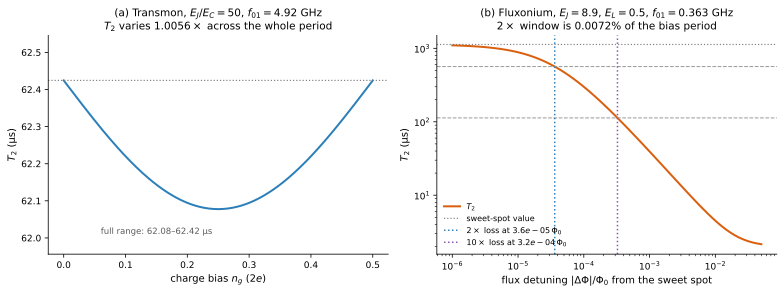

wrote figures/q3_bias_sensitivity.png (+ .pdf)


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) transmon: the whole period, with the y-range made explicit
ax[0].plot(tm_scan.ng, tm_scan.T2_us, lw=2, color="#2c7fb8")
ax[0].axhline(T2_tm0, ls=":", color="0.5", lw=1.2)
lo, hi = float(tm_scan.T2_us.min()), float(tm_scan.T2_us.max())
pad = 0.35 * (hi - lo)
ax[0].set_ylim(lo - pad, hi + pad)
ax[0].set_xlabel(r"charge bias $n_g$ ($2e$)")
ax[0].set_ylabel(r"$T_2$ (µs)")
ax[0].set_title(rf"(a) Transmon, $E_J/E_C=50$, $f_{{01}}={tm_op['freq_GHz']:.2f}$ GHz"
                "\n"
                rf"$T_2$ varies ${tm_var:.4f}\times$ across the whole period")
ax[0].annotate(rf"full range: {lo:.2f}–{hi:.2f} µs",
               xy=(0.25, 0.5 * (lo + hi)), xytext=(0.06, lo - 0.55 * pad),
               fontsize=8.5, color="0.35")

# (b) fluxonium: log detuning, with the 2x and 10x windows marked
det = np.logspace(-6, -1.3, 70)
fx_curve = pd.DataFrame([fluxonium_coherence(**{**FX_OP, "flux": float(0.5 - d)}) for d in det])
fx_curve["detuning"] = det
ax[1].loglog(fx_curve.detuning, fx_curve.T2_us, lw=2, color="#d95f0e", label=r"$T_2$")
ax[1].axhline(T2_fx0, ls=":", color="0.5", lw=1.2, label="sweet-spot value")
ax[1].axhline(T2_fx0 / 2, ls="--", color="0.6", lw=1.0)
ax[1].axhline(T2_fx0 / 10, ls="--", color="0.6", lw=1.0)
ax[1].axvline(d2_fx, color="#2c7fb8", lw=1.5, ls=":",
              label=rf"$2\times$ loss at ${d2_fx:.1e}\,\Phi_0$")
ax[1].axvline(d10_fx, color="#8856a7", lw=1.5, ls=":",
              label=rf"$10\times$ loss at ${d10_fx:.1e}\,\Phi_0$")
ax[1].set_xlabel(r"flux detuning $|\Delta\Phi|/\Phi_0$ from the sweet spot")
ax[1].set_ylabel(r"$T_2$ (µs)")
ax[1].set_title(rf"(b) Fluxonium, $E_J{{=}}8.9$, $E_L{{=}}0.5$, $f_{{01}}={fx_op['freq_GHz']:.3f}$ GHz"
                "\n"
                rf"$2\times$ window is ${100*2*d2_fx:.4f}\%$ of the bias period")
ax[1].legend(frameon=False, fontsize=8, loc="lower left")

fig.tight_layout()
pl.save(fig, "figures/q3_bias_sensitivity.png")
plt.show()
print("wrote figures/q3_bias_sensitivity.png (+ .pdf)")

## 3. Three defensible comparisons, three different answers

Both design planes turned out to be very nearly restatements of $f_{01}$ — correlation $-0.9999$
for the transmon (notebook 02 §5) and $-0.997$ for the fluxonium (notebook 03 §6). Dielectric loss
is the dominant $T_1$ channel in both architectures and it scales with frequency, so **a raw $T_2$
ratio between two qubits at different frequencies partly measures the frequency difference rather
than the architecture.** That is a confound, and Q3 cannot be answered without addressing it.

Three comparisons are computed. They are all defensible and they disagree by more than two orders
of magnitude, which is itself the finding.

| # | Comparison | Controls for | Reads as |
|---|---|---|---|
| 1 | Raw $T_2$, each at its own sweet spot | nothing | "how good is each device as built" |
| 2 | $T_2$ at **matched $f_{01}$** | the frequency confound | "is the *architecture* better at fixed frequency" |
| 3 | **Gate count** $N = T_2 \times \lvert\alpha\rvert$ | what coherence is spent on | "how many operations fit inside the coherence" |

**On metric 3, and on the bound hidden inside it.** A qubit's minimum pulse length is bounded
below by its anharmonicity — drive it faster than $\sim 1/|\alpha|$ and the pulse spectrum overlaps
the $1\!\to\!2$ transition and leaks (Krantz 2019 §IV D 3). So $N \approx T_2|\alpha|$ estimates how
many gates fit inside the coherence time. **Krantz does not write this formula**; it is this
project's heuristic.

**But $|\alpha|$ is not the only bound, and for a fluxonium it is not the binding one.** A resonant
drive cannot be much shorter than *one period of the transition it drives* without the
rotating-wave approximation failing, so $1/f_{01}$ is an equally physical floor on $T_{\rm gate}$.
For a transmon $|\alpha| \ll f_{01}$ (299 MHz against 4.9 GHz) and the two bounds coincide. For this
fluxonium $|\alpha| = 8.7$ GHz against $f_{01} = 0.363$ GHz — the anharmonicity bound would permit a
pulse **24× shorter than one period of the qubit transition**, which is not a gate.

*An earlier version of this notebook noted in prose that "a 0.363 GHz qubit cannot in practice be
driven at its 8.7 GHz anharmonicity limit" and then reported the $|\alpha|$-bounded number as the
headline anyway.* Three bounds are therefore computed side by side below and carried through the
Monte Carlo, because the choice between them is worth as much as the choice between metrics 1–3:

| bound on $T_{\rm gate}$ | reads as | transmon | fluxonium |
|---|---|---|---|
| $1/\lvert\alpha\rvert$ | leakage to $\lvert2\rangle$ only | 299 MHz | 8660 MHz |
| $1/\min(\lvert\alpha\rvert, f_{01})$ | leakage **and** drive period | 299 MHz | 363 MHz |
| $1/f_{01}$ | drive period alone | 4925 MHz | 363 MHz |

Metric 2 additionally requires a **gate count at matched frequency**, which notebook 03 §9B did not
compute — it gave the gate-count ratio only at the two devices' own operating points. That gap is
filled here. Note what the drive-period bound does to it: at matched $f_{01}$ both qubits have the
same $f_{01}$ by construction, so $N = T_2 f_{01}$ and **the gate ratio becomes the $T_2$ ratio
exactly** — including its 42% win rate. The matched-frequency gate-count advantage is an
anharmonicity claim and nothing else.

In [6]:
reset_channel_failures()
# Gate count = T2 / T_gate, and T_gate is set by the largest pulse bandwidth the qubit
# tolerates. Which bandwidth that is, is a modelling choice worth as much as the choice of
# metric itself, so all three defensible bounds are carried through rather than one:
#
#   "alpha" : 1/|alpha|            leakage to |2> only. The textbook bound (Koch Sec. II C,
#                                  Krantz Sec. IV D 3), and what earlier versions used.
#   "both"  : 1/min(|alpha|, f01)  leakage AND the drive-period floor.
#   "f01"   : 1/f01                the drive-period floor alone: a resonant drive cannot be
#                                  much shorter than one period of the transition it drives
#                                  without the rotating-wave approximation failing.
#
# For a transmon |alpha| << f01, so all three coincide. For a fluxonium at the flux sweet
# spot |alpha| = 8.7 GHz against f01 = 0.363 GHz -- a factor of 24 -- so the bound decides
# the answer. See the discussion cell above.
GATE_BOUNDS = ("alpha", "both", "f01")

def gate_bandwidth(alpha_GHz, f01_GHz, bound="alpha"):
    a = abs(alpha_GHz)
    return {"alpha": a, "both": min(a, f01_GHz), "f01": f01_GHz}[bound]

# Gates before decoherence, N = T2 / T_gate. Heuristic; see the markdown above.
def GATE_N(T2_us, alpha_GHz, f01_GHz, bound="alpha"):
    return 1e3 * T2_us * gate_bandwidth(alpha_GHz, f01_GHz, bound)

# ---------------- metric 1: raw ----------------------------------------------
raw_ratio = fx_op["T2_us"] / tm_op["T2_us"]
N_fx_raw = GATE_N(fx_op["T2_us"], alpha_fx, fx_op["freq_GHz"])
N_tm_raw = GATE_N(tm_op["T2_us"], alpha_tm, tm_op["freq_GHz"])

print("METRIC 1 - RAW T2, each at its own sweet spot")
print(f"   fluxonium {fx_op['T2_us']:8.1f} us  f01 = {fx_op['freq_GHz']:.3f} GHz  "
      f"n_th = {n_thermal(fx_op['freq_GHz']):.2f}")
print(f"   transmon  {tm_op['T2_us']:8.1f} us  f01 = {tm_op['freq_GHz']:.3f} GHz  "
      f"n_th = {n_thermal(tm_op['freq_GHz']):.1e}")
print(f"   ratio {raw_ratio:.1f}x   <- confounded: the two sit at very different frequencies")

# ---------------- metric 2: matched frequency --------------------------------
# f01 depends only on the DESIGN, never on the noise amplitudes, so the matched
# designs can be found once and reused (including inside the Monte Carlo below).
def fluxonium_at_frequency(f_target, EJ=8.9, EC=2.5, EL_range=(0.2, 6.0), n=140):
    els = np.linspace(*EL_range, n)
    freqs = np.array([qubit_frequency(make_fluxonium(EJ=EJ, EC=EC, EL=float(e), flux=0.5))
                      for e in els])
    i = int(np.abs(freqs - f_target).argmin())
    return dict(EJ=EJ, EC=EC, EL=float(els[i]), flux=0.5, cutoff=110), float(freqs[i])

def transmon_at_frequency(f_target, min_EJ_EC=50, ncut=60):
    # f01 = sqrt(8 EJ EC) - EC  ->  EJ = (f + EC)^2 / (8 EC); scan EC, keep EJ/EC >= min
    best = None
    for ec in np.linspace(0.01, 0.5, 160):
        ej = (f_target + ec) ** 2 / (8 * ec)
        if ej / ec < min_EJ_EC:
            continue
        r = transmon_coherence(EJ=float(ej), EC=float(ec), ng=0.0, ncut=ncut)
        if best is None or r["T2_us"] > best[0]["T2_us"]:
            best = (r, dict(EJ=float(ej), EC=float(ec), ncut=ncut))
    return best[1], best[0]["freq_GHz"]

MATCH_FREQS = (0.5, 1.0, 2.0)
matched = []
for f_t in MATCH_FREQS:
    fx_des, fx_f = fluxonium_at_frequency(f_t)
    tm_des, tm_f = transmon_at_frequency(f_t)
    fx_r = fluxonium_coherence(**fx_des)
    tm_r = transmon_coherence(**tm_des, ng=0.0)
    a_fx = anharmonicity(make_fluxonium(**fx_des))
    a_tm = anharmonicity(make_transmon(**tm_des, ng=0.0))
    matched.append(dict(
        f01_target=f_t, fx_f01=fx_f, tm_f01=tm_f,
        fx_design=fx_des, tm_design=tm_des,
        fx_T2=fx_r["T2_us"], tm_T2=tm_r["T2_us"], T2_ratio=fx_r["T2_us"] / tm_r["T2_us"],
        fx_alpha=a_fx, tm_alpha=a_tm,
        **{f"fx_N_{b}": GATE_N(fx_r["T2_us"], a_fx, fx_f, b) for b in GATE_BOUNDS},
        **{f"tm_N_{b}": GATE_N(tm_r["T2_us"], a_tm, tm_f, b) for b in GATE_BOUNDS},
        **{f"N_ratio_{b}": (GATE_N(fx_r["T2_us"], a_fx, fx_f, b)
                            / GATE_N(tm_r["T2_us"], a_tm, tm_f, b)) for b in GATE_BOUNDS},
        fx_N=GATE_N(fx_r["T2_us"], a_fx, fx_f), tm_N=GATE_N(tm_r["T2_us"], a_tm, tm_f),
        N_ratio=GATE_N(fx_r["T2_us"], a_fx, fx_f) / GATE_N(tm_r["T2_us"], a_tm, tm_f),
        n_thermal=float(n_thermal(f_t)), tm_EJ_EC=tm_des["EJ"] / tm_des["EC"]))
mt = pd.DataFrame(matched)

# convergence of the transmon basis at the most demanding matched design
_worst = min(matched, key=lambda m: m["tm_design"]["EC"])["tm_design"]
_c60 = transmon_coherence(**{**_worst, "ncut": 60}, ng=0.0)["freq_GHz"]
_c90 = transmon_coherence(**{**_worst, "ncut": 90}, ng=0.0)["freq_GHz"]
assert abs(_c60 - _c90) < 1e-6, "transmon ncut=60 not converged in the matched-frequency scan"

print("\nMETRIC 2 - MATCHED FREQUENCY (transmon held to EJ/EC >= 50)")
display(mt[["f01_target", "fx_f01", "tm_f01", "fx_T2", "tm_T2", "T2_ratio",
            "fx_N", "tm_N", "N_ratio", "tm_EJ_EC", "n_thermal"]].style.format({
    "f01_target": "{:.1f}", "fx_f01": "{:.3f}", "tm_f01": "{:.3f}",
    "fx_T2": "{:.1f}", "tm_T2": "{:.1f}", "T2_ratio": "{:.2f}x",
    "fx_N": "{:,.0f}", "tm_N": "{:,.0f}", "N_ratio": "{:.1f}x",
    "tm_EJ_EC": "{:.0f}", "n_thermal": "{:.3f}"}))
print(f"   transmon basis convergence at the most demanding design "
      f"(EC={_worst['EC']:.3f}): |df01| ncut 60 vs 90 = {abs(_c60-_c90):.1e} GHz")
print(f"   >>> at matched frequency the T2 advantage is only "
      f"{mt.T2_ratio.min():.2f}x - {mt.T2_ratio.max():.2f}x")
print(f"   >>> the gate-count advantage under the LEAKAGE-ONLY bound persists at "
      f"{mt.N_ratio_alpha.min():.0f}x - {mt.N_ratio_alpha.max():.0f}x, because the fluxonium")
print(f"       keeps its huge anharmonicity at every frequency while the transmon must shrink")
print(f"       EC to reach low f01 at fixed EJ/EC -- it buys frequency by giving up anharmonicity.")
print(f"   >>> BUT under the DRIVE-PERIOD bound both qubits sit at the SAME f01 by construction,")
print(f"       so N = T2*f01 and the gate ratio collapses onto the T2 ratio exactly:")
print(f"       {mt.N_ratio_f01.min():.2f}x - {mt.N_ratio_f01.max():.2f}x. The matched-frequency")
print(f"       gate-count advantage is therefore entirely an ANHARMONICITY claim, and it holds")
print(f"       only to the extent that anharmonicity, not frequency, sets the pulse length.")
display(mt[["f01_target"] + [f"N_ratio_{b}" for b in GATE_BOUNDS]].style.format(
    {"f01_target": "{:.1f}", **{f"N_ratio_{b}": "{:,.2f}x" for b in GATE_BOUNDS}}))
print(f"   >>> CAVEAT: the matched transmons need EJ/EC = {mt.tm_EJ_EC.min():.0f}-"
      f"{mt.tm_EJ_EC.max():.0f}, far above the 50-100 of real")
print(f"       devices, and both architectures are thermally populated at 0.5 GHz "
      f"(n_th = {mt.n_thermal.max():.2f}).")
print(f"       Matched-frequency comparison is a CONTROL, not a pair of buildable devices.")

# ---------------- metric 3: gate count at own operating points ---------------
print(f"\nMETRIC 3 - GATE COUNT at each device's own operating point (heuristic)")
print(f"   fluxonium |alpha| = {1e3*abs(alpha_fx):8,.0f} MHz   f01 = {1e3*fx_op['freq_GHz']:7,.0f} MHz")
print(f"   transmon  |alpha| = {1e3*abs(alpha_tm):8,.0f} MHz   f01 = {1e3*tm_op['freq_GHz']:7,.0f} MHz")
gate_raw = {}
for b in GATE_BOUNDS:
    nf = GATE_N(fx_op["T2_us"], alpha_fx, fx_op["freq_GHz"], b)
    nt = GATE_N(tm_op["T2_us"], alpha_tm, tm_op["freq_GHz"], b)
    gate_raw[b] = dict(fluxonium=float(nf), transmon=float(nt), ratio=float(nf / nt))
    lab = {"alpha": "1/|alpha|  (leakage only)", "both": "1/min(|alpha|,f01)",
           "f01": "1/f01  (drive period)"}[b]
    print(f"   bound {lab:26s} fluxonium {nf:12,.0f}   transmon {nt:10,.0f}   "
          f"ratio {nf/nt:9,.2f}x")
_grr = [v["ratio"] for v in gate_raw.values()]
print(f"\n   >>> The gate-count metric alone spans {max(_grr)/min(_grr):,.0f}x across its own")
print(f"   >>> pulse-length bounds. The headline 524x assumes the fluxonium is driven at its")
print(f"   >>> 8.7 GHz anharmonicity limit, i.e. {abs(alpha_fx)/fx_op['freq_GHz']:.0f}x faster than one period of its")
print(f"   >>> own {1e3*fx_op['freq_GHz']:.0f} MHz transition. Under the drive-period bound the advantage is")
print(f"   >>> {gate_raw['f01']['ratio']:.2f}x -- the transmon's higher frequency very nearly cancels the")
print(f"   >>> fluxonium's longer T2. THIS IS THE SINGLE LARGEST REMAINING UNCERTAINTY IN Q3.")

assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

METRICS = {
    "raw_T2_ratio": float(raw_ratio),
    "matched_frequency_T2_ratio": {str(m["f01_target"]): float(m["T2_ratio"]) for m in matched},
    "matched_frequency_gate_ratio": {str(m["f01_target"]): float(m["N_ratio"]) for m in matched},
    "gate_count_ratio_own_operating_points": float(N_fx_raw / N_tm_raw),
    "gate_pulse_bound_note": "N = T2 / T_gate with T_gate = 1/(pulse bandwidth). 'alpha' is "
                             "the leakage bound used for the headline; 'f01' is the "
                             "drive-period floor; 'both' takes the smaller bandwidth. They "
                             "coincide for a transmon and differ by 24x for this fluxonium.",
    "gate_count_by_pulse_bound_own_operating_points": gate_raw,
    "matched_frequency_gate_ratio_by_pulse_bound": {
        b: {str(m["f01_target"]): float(m[f"N_ratio_{b}"]) for m in matched}
        for b in GATE_BOUNDS},
}
print(f"\n>>> THE ANSWER TO Q3 SPANS {METRICS['gate_count_ratio_own_operating_points']/mt.T2_ratio.min():,.0f}x "
      f"DEPENDING ON THE METRIC:")
print(f"       raw T2                        : {raw_ratio:8.1f}x")
print(f"       T2 at matched frequency       : {mt.T2_ratio.min():8.2f}x - {mt.T2_ratio.max():.2f}x")
print(f"       gate count at matched freq    : {mt.N_ratio.min():8.0f}x - {mt.N_ratio.max():.0f}x")
print(f"       gate count at own op. points  : {N_fx_raw/N_tm_raw:8,.0f}x")
mt.drop(columns=["fx_design", "tm_design"]).to_csv("data/q3_metric_comparison.csv", index=False)
print("\nwrote data/q3_metric_comparison.csv")

METRIC 1 - RAW T2, each at its own sweet spot
   fluxonium   1129.7 us  f01 = 0.363 GHz  n_th = 0.45
   transmon      62.4 us  f01 = 4.925 GHz  n_th = 1.4e-07
   ratio 18.1x   <- confounded: the two sit at very different frequencies



METRIC 2 - MATCHED FREQUENCY (transmon held to EJ/EC >= 50)


,f01_target,fx_f01,tm_f01,fx_T2,tm_T2,T2_ratio,fx_N,tm_N,N_ratio,tm_EJ_EC,n_thermal
0,0.5,0.495,0.500,834.8,387.3,2.16x,"6,937,970","4,061",1708.6x,325,0.253
1,1.0,1.004,1.000,387.2,284.3,1.36x,"2,798,233","2,909",962.0x,1275,0.043
2,2.0,1.993,2.000,168.1,157.3,1.07x,"993,813","1,591",624.8x,5050,0.002


   transmon basis convergence at the most demanding design (EC=0.010): |df01| ncut 60 vs 90 = 1.7e-14 GHz
   >>> at matched frequency the T2 advantage is only 1.07x - 2.16x
   >>> the gate-count advantage under the LEAKAGE-ONLY bound persists at 625x - 1709x, because the fluxonium
       keeps its huge anharmonicity at every frequency while the transmon must shrink
       EC to reach low f01 at fixed EJ/EC -- it buys frequency by giving up anharmonicity.
   >>> BUT under the DRIVE-PERIOD bound both qubits sit at the SAME f01 by construction,
       so N = T2*f01 and the gate ratio collapses onto the T2 ratio exactly:
       1.07x - 2.14x. The matched-frequency
       gate-count advantage is therefore entirely an ANHARMONICITY claim, and it holds
       only to the extent that anharmonicity, not frequency, sets the pulse length.


,f01_target,N_ratio_alpha,N_ratio_both,N_ratio_f01
0,0.5,"1,708.65x",101.80x,2.14x
1,1.0,961.95x,133.61x,1.37x
2,2.0,624.81x,210.59x,1.07x


   >>> CAVEAT: the matched transmons need EJ/EC = 325-5050, far above the 50-100 of real
       devices, and both architectures are thermally populated at 0.5 GHz (n_th = 0.25).
       Matched-frequency comparison is a CONTROL, not a pair of buildable devices.

METRIC 3 - GATE COUNT at each device's own operating point (heuristic)
   fluxonium |alpha| =    8,660 MHz   f01 =     363 MHz
   transmon  |alpha| =      299 MHz   f01 =   4,925 MHz
   bound 1/|alpha|  (leakage only)  fluxonium    9,782,750   transmon     18,652   ratio    524.48x
   bound 1/min(|alpha|,f01)         fluxonium      410,562   transmon     18,652   ratio     22.01x
   bound 1/f01  (drive period)      fluxonium      410,562   transmon    307,434   ratio      1.34x

   >>> The gate-count metric alone spans 393x across its own
   >>> pulse-length bounds. The headline 524x assumes the fluxonium is driven at its
   >>> 8.7 GHz anharmonicity limit, i.e. 24x faster than one period of its
   >>> own 363 MHz transition. Un

### 3.1 Settling the pulse bound by simulation

The gate-count range above ($524\times$ / $22\times$ / $1.34\times$) is wide enough to make
the metric nearly uninformative, and the disagreement is not about noise — it is about how
short a pulse each qubit tolerates. That is a question with a computable answer, so it is
computed here rather than argued.

**Method.** For each architecture we integrate the **lab-frame** Schrödinger equation with
**no rotating-wave approximation**, on a six-level truncation of the `scqubits` eigenbasis,
driven through the charge operator $\hat n$ (a capacitively coupled microwave line). The
envelope is a truncated Gaussian with $\sigma = T/4$. At each gate duration $T$ we
**calibrate the gate the way an experimentalist would**, optimising three parameters
simultaneously:

- the drive amplitude (to close the rotation),
- the **DRAG** coefficient (Motzoi *et al.* 2009) on the quadrature channel,
- the drive frequency, absorbing the AC Stark shift.

The figure of merit is the average gate fidelity of an $X$ gate evaluated on the
computational subspace, $F = (|{\rm Tr}(X^\dagger V)|^2 + {\rm Tr}(V^\dagger V))/6$ with
$V = P U P$, so **population that leaks out of $\{|0\rangle, |1\rangle\}$ is counted as
error** rather than quietly dropped. A virtual-$Z$ is optimised out, as it would be in
hardware. $T_{\rm gate}$ is then the shortest duration reaching a target error.

**Why this is not a formality.** The anharmonicity argument treats $|\alpha|$ as the whole
story, but the drive couples to the leakage transition through a *matrix element*, and the
fluxonium's is badly placed: at the sweet spot
$|\langle 1|\hat n|2\rangle| / |\langle 0|\hat n|1\rangle| = 10.2$, against $1.37$ for the
transmon. The drive is ten times better at causing leakage than at driving the qubit, so the
effective figure of merit is $|\alpha|$ *divided by* that ratio. No hand-argument recovers
this; the simulation does.

> **This is a coarse calibration, and the resulting $T_{\rm gate}$ is therefore an *upper
> bound*.** Three parameters and a fixed Gaussian shape is far from optimal control — GRAPE
> or CRAB over a free pulse shape would find shorter gates for both architectures, and there
> is no reason to assume it would shorten them equally. The number below is a much better
> estimate than either naive bound, not a final answer. The optimiser is also not reliably
> converged at the shortest durations, which is visible as non-monotonicity in the error
> curve and is reported rather than smoothed.

In [7]:
import qutip as qt
from scipy.integrate import quad

GATE_LEVELS = 6
ERR_TARGET = 1e-3          # a standard single-qubit gate-error target

def _drive_system(qubit, nlev=GATE_LEVELS):
    qubit.truncated_dim = nlev            # scqubits defaults to 6; n_operator respects it
    esys = qubit.eigensys(evals_count=nlev)
    f = esys[0] - esys[0][0]
    n = np.array(qubit.n_operator(energy_esys=esys))[:nlev, :nlev]
    return f, n - np.diag(np.diag(n))     # the drive couples off-diagonally

def _envelope(t, T):
    sig = T / 4.0
    g = np.exp(-((t - T / 2) ** 2) / (2 * sig ** 2))
    g0 = np.exp(-((T / 2) ** 2) / (2 * sig ** 2))
    return (g - g0) / (1 - g0)

def gate_error(f, n, T, amp, drag, det, nlev=GATE_LEVELS):
    # Lab frame, no RWA. Energies in GHz, times in ns, so H carries a factor 2*pi.
    wd = f[1] + det
    alpha = (f[2] - f[1]) - f[1]
    H0 = qt.Qobj(2 * np.pi * np.diag(f)); N = qt.Qobj(2 * np.pi * n)
    sig = T / 4.0
    g0 = np.exp(-((T / 2) ** 2) / (2 * sig ** 2))
    def eps(t, *a, **k):
        g = np.exp(-((t - T / 2) ** 2) / (2 * sig ** 2))
        I = amp * (g - g0) / (1 - g0)
        dI = amp * (-(t - T / 2) / sig ** 2) * g / (1 - g0)
        Q = drag * dI / (2 * np.pi * alpha)          # DRAG on the quadrature channel
        return I * np.cos(2 * np.pi * wd * t) + Q * np.sin(2 * np.pi * wd * t)
    U = qt.sesolve([H0, [N, eps]], qt.qeye(nlev), [0, T],
                   options={"atol": 1e-10, "rtol": 1e-8, "nsteps": 10**7}).states[-1].full()
    R = np.diag(np.exp(1j * 2 * np.pi * wd * np.arange(nlev) * T))    # rotating frame
    Uq = (R @ U)[:2, :2]                                              # computational block
    Xt = np.array([[0, 1], [1, 0]], dtype=complex)
    def err(th):                                                      # virtual Z, as in hardware
        V = np.diag([1, np.exp(1j * th)]) @ Uq
        F = (abs(np.trace(Xt.conj().T @ V)) ** 2 + np.trace(V.conj().T @ V).real) / 6
        return 1 - F.real
    return minimize_scalar(err, bounds=(-np.pi, np.pi), method="bounded").fun

def calibrate_gate(f, n, T, nlev=GATE_LEVELS, maxfev=140):
    # pi-pulse amplitude in the RWA: 2*pi*|n01|*int(I dt) = pi
    area = quad(lambda t: _envelope(t, T), 0, T)[0]
    a0 = 1.0 / (2 * abs(n[0, 1]) * area)
    best = None
    for d0 in (0.0, -1.0, 1.0):                       # DRAG sign convention is not assumed
        r = minimize(lambda x: np.log10(max(gate_error(f, n, T, x[0], x[1], x[2], nlev), 1e-14)),
                     np.array([a0, d0, 0.0]), method="Nelder-Mead",
                     options={"xatol": 1e-6, "fatol": 1e-3, "maxfev": maxfev})
        if best is None or r.fun < best.fun:
            best = r
    return 10 ** best.fun, best.x

DURATIONS = {"transmon":  [4.0, 5.0, 5.5, 6.0, 8.0, 12.0],
             "fluxonium": [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]}
QUBITS = {"transmon":  make_transmon(**TM_OP, ng=0.0),
          "fluxonium": make_fluxonium(**FX_OP)}

print("drive matrix elements (why |alpha| alone is the wrong figure of merit):")
gate_rows, tmin, tbracket = [], {}, {}
for lab, q in QUBITS.items():
    f, n = _drive_system(q)
    ratio = abs(n[1, 2]) / abs(n[0, 1])
    print(f"   {lab:9s} |<0|n|1>| = {abs(n[0,1]):.4f}   |<1|n|2>| = {abs(n[1,2]):.4f}   "
          f"leakage/drive ratio = {ratio:5.2f}")
    for T in DURATIONS[lab]:
        e, x = calibrate_gate(f, n, T)
        gate_rows.append(dict(architecture=lab, T_ns=T, gate_error=float(e),
                              amp=float(x[0]), drag=float(x[1]), detuning_GHz=float(x[2]),
                              leak_drive_ratio=float(ratio)))
        print(f"      T = {T:5.2f} ns -> error {e:.3e}   (amp {x[0]:.3f}, DRAG {x[1]:+.2f}, "
              f"Stark {1e3*x[2]:+6.1f} MHz)")
    # A longer gate can always emulate a shorter one padded with idle, so the true error
    # is non-increasing in T. The optimiser does not respect that (it is noisy at short
    # durations), so take the running minimum from the left before reading off T_min --
    # and report the BRACKET, since the grid spacing and the optimiser both limit it.
    sub = sorted([r for r in gate_rows if r["architecture"] == lab],
                 key=lambda r: r["T_ns"])
    env, run = [], np.inf
    for r in sub:
        run = min(run, r["gate_error"]); env.append(run)
    below = [r["T_ns"] for r, e in zip(sub, env) if e < ERR_TARGET]
    tmin[lab] = float(min(below)) if below else float("nan")
    above = [r["T_ns"] for r, e in zip(sub, env) if e >= ERR_TARGET and r["T_ns"] < tmin[lab]]
    tbracket[lab] = (float(max(above)) if above else float("nan"), tmin[lab])
    if any(a > b for a, b in zip([r["gate_error"] for r in sub], env)):
        print(f"      NOTE {lab}: the raw error curve is non-monotonic in T, which is "
              f"optimiser noise, not physics.\n           A monotone envelope is used to read "
              f"off T_gate, and the bracket is reported.")

gates = pd.DataFrame(gate_rows)
gates.to_csv("data/q3_pulse_simulation.csv", index=False)
print(f"\n{len(gates)} calibrated gates -> data/q3_pulse_simulation.csv")

T2_OP = {"transmon": tm_op["T2_us"], "fluxonium": fx_op["T2_us"]}
N_sim = {k: 1e3 * T2_OP[k] / tmin[k] for k in tmin}
sim_ratio = N_sim["fluxonium"] / N_sim["transmon"]
print(f"\nshortest simulated gate with error < {ERR_TARGET:.0e} (an UPPER bound on T_gate):")
for k in ("transmon", "fluxonium"):
    lo, hi = tbracket[k]
    print(f"   {k:9s} T_gate = {tmin[k]:5.2f} ns  (bracketed by the grid: {lo:.2f}-{hi:.2f} ns)"
          f"   T2 = {T2_OP[k]:8.1f} us   N = {N_sim[k]:10,.0f}")
# the ratio inherits both brackets, so quote it as a range too
r_lo = (1e3 * T2_OP["fluxonium"] / tbracket["fluxonium"][1]) / (1e3 * T2_OP["transmon"] / tbracket["transmon"][0])
r_hi = (1e3 * T2_OP["fluxonium"] / tbracket["fluxonium"][0]) / (1e3 * T2_OP["transmon"] / tbracket["transmon"][1])
print(f"\n>>> SIMULATED gate-count ratio = {sim_ratio:,.0f}x  "
      f"(grid+optimiser bracket: {min(r_lo, r_hi):,.0f}-{max(r_lo, r_hi):,.0f}x)")
print(f">>> versus the three analytic bounds: "
      f"{gate_raw['alpha']['ratio']:,.0f}x (1/|alpha|), "
      f"{gate_raw['both']['ratio']:.1f}x (1/min), {gate_raw['f01']['ratio']:.2f}x (1/f01)")
print(">>> The simulation lands between the min-bound and the leakage-only bound, and rules")
print(">>> BOTH naive extremes out. The fluxonium does convert coherence into operations more")
print(">>> efficiently -- by tens, not by ~500x and not by ~1x.")
print(f">>> Mechanism: its anharmonicity is {abs(alpha_fx)/abs(alpha_tm):.0f}x larger, but its drive couples")
print(f">>> {gates[gates.architecture=='fluxonium'].leak_drive_ratio.iloc[0]/gates[gates.architecture=='transmon'].leak_drive_ratio.iloc[0]:.1f}x more strongly to the leakage transition, which eats most of that.")

METRICS["gate_count_simulated"] = {
    "method": "lab-frame Schrodinger, no RWA, 6 levels, charge drive, Gaussian envelope; "
              "amplitude + DRAG + Stark detuning calibrated at each duration; average gate "
              "fidelity on the computational subspace so leakage counts as error",
    "error_target": ERR_TARGET,
    "T_gate_ns": tmin, "T_gate_bracket_ns": tbracket, "N_gates": N_sim,
    "ratio": float(sim_ratio), "ratio_bracket": [float(min(r_lo, r_hi)), float(max(r_lo, r_hi))],
    "caveat": "coarse 3-parameter calibration with a fixed Gaussian shape, so T_gate is an "
              "UPPER bound; optimal control would shorten both, not necessarily equally. The "
              "optimiser is not reliably converged at the shortest durations.",
}

drive matrix elements (why |alpha| alone is the wrong figure of merit):
   transmon  |<0|n|1>| = 1.0878   |<1|n|2>| = 1.4903   leakage/drive ratio =  1.37


      T =  4.00 ns -> error 2.355e-02   (amp 0.178, DRAG -1.32, Stark  -68.3 MHz)


      T =  5.00 ns -> error 4.488e-03   (amp 0.147, DRAG -1.41, Stark  -56.9 MHz)


      T =  5.50 ns -> error 1.337e-03   (amp 0.136, DRAG -1.44, Stark  -51.2 MHz)


      T =  6.00 ns -> error 3.133e-03   (amp 0.133, DRAG -1.37, Stark  -38.0 MHz)


...

      T =  1.50 ns -> error 5.737e-02   (amp 4.871, DRAG -37.04, Stark +226.0 MHz)


      T =  2.00 ns -> error 7.273e-03   (amp 6.988, DRAG -24.27, Stark  +63.7 MHz)


      T =  2.50 ns -> error 2.220e-03   (amp 7.634, DRAG -18.47, Stark  -10.8 MHz)


      T =  3.00 ns -> error 7.720e-07   (amp 7.286, DRAG -19.49, Stark  -30.1 MHz)


      T =  4.00 ns -> error 3.648e-06   (amp 5.435, DRAG +0.05, Stark -101.7 MHz)
      NOTE fluxonium: the raw error curve is non-monotonic in T, which is optimiser noise, not physics.
           A monotone envelope is used to read off T_gate, and the bracket is reported.

12 calibrated gates -> data/q3_pulse_simulation.csv

shortest simulated gate with error < 1e-03 (an UPPER bound on T_gate):
   transmon  T_gate =  8.00 ns  (bracketed by the grid: 6.00-8.00 ns)   T2 =     62.4 us   N =      7,803
   fluxonium T_gate =  3.00 ns  (bracketed by the grid: 2.50-3.00 ns)   T2 =   1129.7 us   N =    376,571

>>> SIMULATED gate-count ratio = 48x  (grid+optimiser bracket: 36-58x)
>>> versus the three analytic bounds: 524x (1/|alpha|), 22.0x (1/min), 1.34x (1/f01)
>>> The simulation lands between the min-bound and the leakage-only bound, and rules
>>> BOTH naive extremes out. The fluxonium does convert coherence into operations more
>>> efficiently -- by tens, not by ~500x and not by ~1x.
>>>

### Figure — where the pulse bound actually lands

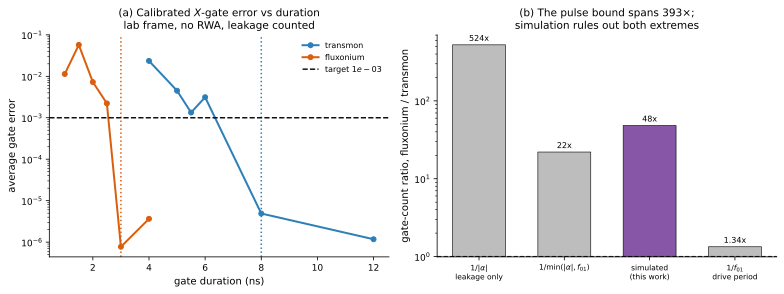

wrote figures/q3_pulse_bound.png (+ .pdf)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

for lab, col in (("transmon", "#2c7fb8"), ("fluxonium", "#d95f0e")):
    g = gates[gates.architecture == lab].sort_values("T_ns")
    ax[0].semilogy(g.T_ns, g.gate_error, "o-", color=col, lw=2, ms=5, label=lab)
    ax[0].axvline(tmin[lab], ls=":", color=col, lw=1.5)
ax[0].axhline(ERR_TARGET, ls="--", color="k", lw=1.4, label=rf"target ${ERR_TARGET:.0e}$")
ax[0].set_xlabel("gate duration (ns)"); ax[0].set_ylabel("average gate error")
ax[0].set_title("(a) Calibrated $X$-gate error vs duration\nlab frame, no RWA, leakage counted")
ax[0].legend(frameon=False, fontsize=8)

labels = [r"$1/|\alpha|$" "\n" "leakage only", r"$1/\min(|\alpha|,f_{01})$",
          "simulated\n(this work)", r"$1/f_{01}$" "\n" "drive period"]
vals = [gate_raw["alpha"]["ratio"], gate_raw["both"]["ratio"], sim_ratio,
        gate_raw["f01"]["ratio"]]
cols = ["#bdbdbd", "#bdbdbd", "#8856a7", "#bdbdbd"]
ax[1].bar(range(4), vals, color=cols, width=0.62, edgecolor="k", linewidth=0.6)
ax[1].set_yscale("log"); ax[1].axhline(1, color="k", ls="--", lw=1.2)
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(labels, fontsize=7.5)
for i, v in enumerate(vals):
    ax[1].annotate(f"{v:,.0f}x" if v >= 10 else f"{v:.2f}x", xy=(i, v),
                   xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
ax[1].set_ylabel("gate-count ratio, fluxonium / transmon")
ax[1].set_title("(b) The pulse bound spans 393$\\times$;\nsimulation rules out both extremes")
fig.tight_layout()
pl.save(fig, "figures/q3_pulse_bound.png")
plt.show()
print("wrote figures/q3_pulse_bound.png (+ .pdf)")

## 4. Monte Carlo over the noise-amplitude uncertainty

$Q_{\rm cap}$, $A_\Phi$, $A_{cc}$ and $A_{ng}$ are literature point estimates with roughly a decade
of spread each, and every number above inherits that spread. The project's stated position is that
*comparative* conclusions are robust while *absolute* values are not; this section tests it for the
Q3 comparison specifically.

**Sampling.** Each amplitude is drawn log-uniformly over its literature band. Two correlation
structures are run, because the choice is a modelling assumption that changes the answer:

- **shared** — $Q_{\rm cap}$ and $A_{cc}$ are drawn *once per sample* and given to both
  architectures. This is the "both qubits come off the same fabrication process" assumption, and it
  is the honest default for an architecture comparison, because it cancels the common-mode material
  uncertainty and isolates the architectural difference.
- **independent** — every amplitude drawn separately per architecture. This is the "compare a
  fluxonium from one lab against a transmon from another" assumption and necessarily widens the
  spread.

$A_\Phi$ affects only the fluxonium and $A_{ng}$ only the transmon, so those are always drawn once.

**Statistics.** The previous version reported a 90% CI from $N=60$ samples with no evidence that the
interval had converged. Here $N=400$, the CI on the median is obtained by **bootstrap** (2000
resamples) rather than read off raw percentiles, and a running-CI trace demonstrates that the
interval has settled. All three metrics from §3 are carried through, so the reported robustness is
metric-specific rather than a single number that silently assumes the raw ratio.

In [9]:
reset_channel_failures()
rng = np.random.default_rng(20260907)
N_MC = 400

# literature bands (decades), same as the superseded version so the comparison is like-for-like
BANDS = {"Q_cap": (5, 7), "A_flux": (-6, -5), "A_cc": (-7, -6), "A_ng": (-4, -3)}

# the matched-frequency design pair used inside the MC: 1.0 GHz, the middle of the three
FX_MATCH = matched[1]["fx_design"]
TM_MATCH = matched[1]["tm_design"]
print(f"matched-frequency pair used in the MC: fluxonium EL={FX_MATCH['EL']:.3f} "
      f"(f01={matched[1]['fx_f01']:.3f} GHz), transmon EJ/EC={matched[1]['tm_EJ_EC']:.0f} "
      f"(f01={matched[1]['tm_f01']:.3f} GHz)")

def draw(mode):
    q_f = 10 ** rng.uniform(*BANDS["Q_cap"])
    c_f = 10 ** rng.uniform(*BANDS["A_cc"])
    q_t, c_t = (q_f, c_f) if mode == "shared" else (10 ** rng.uniform(*BANDS["Q_cap"]),
                                                    10 ** rng.uniform(*BANDS["A_cc"]))
    return dict(Q_cap_fx=q_f, A_cc_fx=c_f, Q_cap_tm=q_t, A_cc_tm=c_t,
                A_flux=10 ** rng.uniform(*BANDS["A_flux"]),
                A_ng=10 ** rng.uniform(*BANDS["A_ng"]))

samples = []
for mode in ("shared", "independent"):
    for _ in range(N_MC):
        s = draw(mode)
        fx_raw = fluxonium_coherence(**FX_OP, Q_cap=s["Q_cap_fx"],
                                     A_flux=s["A_flux"], A_cc=s["A_cc_fx"])
        tm_raw = transmon_coherence(**TM_OP, ng=0.0, Q_cap=s["Q_cap_tm"],
                                    A_ng=s["A_ng"], A_cc=s["A_cc_tm"])
        fx_m = fluxonium_coherence(**FX_MATCH, Q_cap=s["Q_cap_fx"],
                                   A_flux=s["A_flux"], A_cc=s["A_cc_fx"])
        tm_m = transmon_coherence(**TM_MATCH, ng=0.0, Q_cap=s["Q_cap_tm"],
                                  A_ng=s["A_ng"], A_cc=s["A_cc_tm"])
        samples.append(dict(
            mode=mode, **s,
            fx_T2_raw=fx_raw["T2_us"], tm_T2_raw=tm_raw["T2_us"],
            ratio_raw=fx_raw["T2_us"] / tm_raw["T2_us"],
            fx_T2_matched=fx_m["T2_us"], tm_T2_matched=tm_m["T2_us"],
            ratio_matched=fx_m["T2_us"] / tm_m["T2_us"],
            **{f"ratio_gate_matched_{b}": (
                GATE_N(fx_m["T2_us"], matched[1]["fx_alpha"], matched[1]["fx_f01"], b) /
                GATE_N(tm_m["T2_us"], matched[1]["tm_alpha"], matched[1]["tm_f01"], b))
               for b in GATE_BOUNDS},
            **{f"ratio_gate_raw_{b}": (
                GATE_N(fx_raw["T2_us"], alpha_fx, fx_op["freq_GHz"], b) /
                GATE_N(tm_raw["T2_us"], alpha_tm, tm_op["freq_GHz"], b))
               for b in GATE_BOUNDS},
            ratio_gate_matched=(
                GATE_N(fx_m["T2_us"], matched[1]["fx_alpha"], matched[1]["fx_f01"]) /
                GATE_N(tm_m["T2_us"], matched[1]["tm_alpha"], matched[1]["tm_f01"])),
            ratio_gate_raw=(GATE_N(fx_raw["T2_us"], alpha_fx, fx_op["freq_GHz"]) /
                            GATE_N(tm_raw["T2_us"], alpha_tm, tm_op["freq_GHz"]))))
mc = pd.DataFrame(samples)
mc.to_csv("data/q3_monte_carlo.csv", index=False)
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"
print(f"\n{len(mc)} samples ({N_MC} per correlation mode) -> data/q3_monte_carlo.csv")

# ---------------- bootstrap CI on the median ---------------------------------
def bootstrap_median_ci(x, n_boot=2000, alpha=0.10, seed=0):
    x = np.asarray(x, dtype=float)
    r = np.random.default_rng(seed)
    meds = np.median(r.choice(x, size=(n_boot, x.size), replace=True), axis=1)
    return float(np.median(x)), float(np.percentile(meds, 100 * alpha / 2)), \
           float(np.percentile(meds, 100 * (1 - alpha / 2)))

METRIC_COLS = [("ratio_raw", "raw T2"),
               ("ratio_matched", "T2 at matched f01 = 1 GHz"),
               ("ratio_gate_matched", "gate count at matched f01"),
               ("ratio_gate_raw", "gate count at own op. points"),
               ("ratio_gate_raw_both", "gate count, own op. pts, min(|a|,f01) bound"),
               ("ratio_gate_raw_f01", "gate count, own op. pts, drive-period bound"),
               ("ratio_gate_matched_f01", "gate count at matched f01, drive-period bound")]

mc_summary = []
for mode in ("shared", "independent"):
    sub = mc[mc["mode"] == mode]
    for col, label in METRIC_COLS:
        med, lo_ci, hi_ci = bootstrap_median_ci(sub[col])
        p5, p95 = np.percentile(sub[col], [5, 95])
        mc_summary.append(dict(mode=mode, metric=label, median=med,
                               ci_lo=lo_ci, ci_hi=hi_ci, spread_p5=p5, spread_p95=p95,
                               win_fraction=float((sub[col] > 1).mean())))
mc_summary = pd.DataFrame(mc_summary)
mc_summary.to_csv("data/q3_monte_carlo_summary.csv", index=False)
display(mc_summary.style.format({"median": "{:,.2f}", "ci_lo": "{:,.2f}", "ci_hi": "{:,.2f}",
                                 "spread_p5": "{:,.2f}", "spread_p95": "{:,.2f}",
                                 "win_fraction": "{:.1%}"}))
print("   median / ci_lo / ci_hi  = median ratio and its 90% BOOTSTRAP CI (uncertainty in the median)")
print("   spread_p5 / spread_p95  = 5th-95th percentile of the SAMPLES (spread across the band)")
print("   win_fraction            = fraction of samples in which the fluxonium exceeds the transmon")

# ---------------- has the CI converged? --------------------------------------
shared = mc[mc["mode"] == "shared"]
trace = []
for n in (25, 50, 60, 100, 150, 200, 300, 400):
    for col, label in METRIC_COLS[:2]:
        med, lo_ci, hi_ci = bootstrap_median_ci(shared[col].values[:n], n_boot=1000)
        trace.append(dict(n=n, metric=label, median=med, ci_lo=lo_ci, ci_hi=hi_ci,
                          ci_width_rel=(hi_ci - lo_ci) / med))
trace = pd.DataFrame(trace)
print("\nCONVERGENCE OF THE 90% CI WITH SAMPLE SIZE (shared mode):")
display(trace.pivot(index="n", columns="metric", values="ci_width_rel")
        .style.format("{:.1%}").set_caption("relative width of the 90% CI on the median"))
w60 = trace[(trace.n == 60) & (trace.metric == "raw T2")].ci_width_rel.iloc[0]
w400 = trace[(trace.n == 400) & (trace.metric == "raw T2")].ci_width_rel.iloc[0]
print(f"   at N=60 (the superseded sample size) the CI on the median raw ratio is "
      f"{w60:.0%} wide;")
print(f"   at N=400 it is {w400:.0%} wide. The old N=60 interval was not demonstrably converged.")

print("\n" + "=" * 74)
print("WHAT SURVIVES THE NOISE-AMPLITUDE UNCERTAINTY:")
for col, label in METRIC_COLS:
    s = mc_summary[(mc_summary["mode"] == "shared") & (mc_summary.metric == label)].iloc[0]
    i = mc_summary[(mc_summary["mode"] == "independent") & (mc_summary.metric == label)].iloc[0]
    verdict = ("ROBUST - fluxonium wins in every sample" if s.win_fraction == 1.0 else
               f"NOT ROBUST - fluxonium wins in only {s.win_fraction:.0%} of samples")
    print(f"   {label:32s} median {s['median']:9,.2f}x  [{s.spread_p5:,.2f}, {s.spread_p95:,.2f}]  {verdict}")
    print(f"   {'':32s} independent sampling: median {i['median']:,.2f}x, "
          f"win {i.win_fraction:.0%}")

matched-frequency pair used in the MC: fluxonium EL=1.577 (f01=1.004 GHz), transmon EJ/EC=1275 (f01=1.000 GHz)



800 samples (400 per correlation mode) -> data/q3_monte_carlo.csv


,mode,metric,median,ci_lo,ci_hi,spread_p5,spread_p95,win_fraction
0,shared,raw T2,11.25,10.16,12.14,3.59,21.08,100.0%
1,shared,T2 at matched f01 = 1 GHz,0.86,0.78,0.94,0.27,1.58,42.0%
2,shared,gate count at matched f01,605.95,549.87,662.22,190.90,"1,114.27",100.0%
3,shared,gate count at own op. points,326.10,294.34,351.84,103.90,610.84,100.0%
4,shared,"gate count, own op. pts, min(|a|,f01) bound",13.69,12.35,14.77,4.36,25.64,100.0%
5,shared,"gate count, own op. pts, drive-period bound",0.83,0.75,0.90,0.26,1.56,40.2%
6,shared,"gate count at matched f01, drive-period bound",0.86,0.78,0.94,0.27,1.58,42.5%
7,independent,raw T2,9.74,8.78,11.46,1.39,92.57,97.8%
8,independent,T2 at matched f01 = 1 GHz,0.74,0.66,0.89,0.10,7.28,41.8%
9,independent,gate count at matched f01,524.86,465.84,625.27,72.79,"5,144.61",100.0%


   median / ci_lo / ci_hi  = median ratio and its 90% BOOTSTRAP CI (uncertainty in the median)
   spread_p5 / spread_p95  = 5th-95th percentile of the SAMPLES (spread across the band)
   win_fraction            = fraction of samples in which the fluxonium exceeds the transmon

CONVERGENCE OF THE 90% CI WITH SAMPLE SIZE (shared mode):


metric,T2 at matched f01 = 1 GHz,raw T2
n,,
25,68.4%,67.5%
50,49.8%,52.1%
60,51.4%,52.1%
100,49.8%,46.9%
150,35.6%,36.8%
200,31.3%,31.8%
300,21.2%,20.0%
400,19.0%,17.8%


   at N=60 (the superseded sample size) the CI on the median raw ratio is 52% wide;
   at N=400 it is 18% wide. The old N=60 interval was not demonstrably converged.

WHAT SURVIVES THE NOISE-AMPLITUDE UNCERTAINTY:
   raw T2                           median     11.25x  [3.59, 21.08]  ROBUST - fluxonium wins in every sample
                                    independent sampling: median 9.74x, win 98%
   T2 at matched f01 = 1 GHz        median      0.86x  [0.27, 1.58]  NOT ROBUST - fluxonium wins in only 42% of samples
                                    independent sampling: median 0.74x, win 42%
   gate count at matched f01        median    605.95x  [190.90, 1,114.27]  ROBUST - fluxonium wins in every sample
                                    independent sampling: median 524.86x, win 100%
   gate count at own op. points     median    326.10x  [103.90, 610.84]  ROBUST - fluxonium wins in every sample
                                    independent sampling: median 282.22x, win 100%
  

### Figure — robustness, per metric

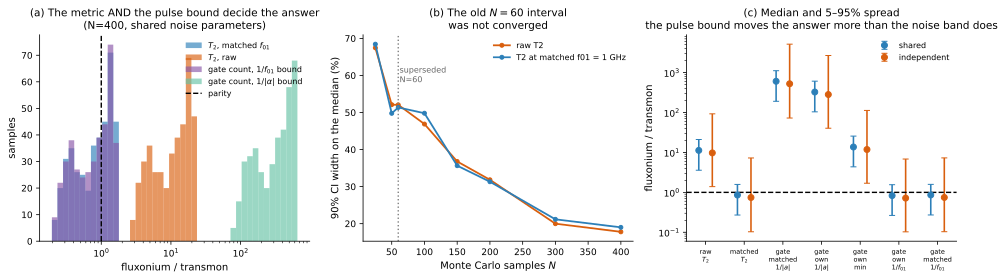

wrote figures/q3_robustness.png (+ .pdf)


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.0))
sh = mc[mc["mode"] == "shared"]

# (a) distribution of the ratio, per metric, on a log axis
cols = ["ratio_matched", "ratio_raw", "ratio_gate_raw_f01", "ratio_gate_raw"]
labs = [r"$T_2$, matched $f_{01}$", r"$T_2$, raw",
        r"gate count, $1/f_{01}$ bound", r"gate count, $1/|\alpha|$ bound"]
colours = ["#2c7fb8", "#d95f0e", "#8856a7", "#66c2a5"]
bins = np.logspace(np.log10(max(sh[cols].values.min(), 1e-2)),
                   np.log10(sh[cols].values.max()), 45)
for c, l, col in zip(cols, labs, colours):
    ax[0].hist(sh[c], bins=bins, alpha=0.65, color=col, label=l)
ax[0].axvline(1, color="k", ls="--", lw=1.4, label="parity")
ax[0].set_xscale("log")
ax[0].set_xlabel(r"fluxonium / transmon")
ax[0].set_ylabel("samples")
ax[0].set_title(f"(a) The metric AND the pulse bound decide the answer\n"
                f"(N={N_MC}, shared noise parameters)")
ax[0].legend(frameon=False, fontsize=8)

# (b) CI convergence
for l, col in zip(trace.metric.unique(), ["#d95f0e", "#2c7fb8"]):
    t = trace[trace.metric == l]
    ax[1].plot(t.n, 100 * t.ci_width_rel, "o-", color=col, lw=1.8, ms=4, label=l)
ax[1].axvline(60, color="0.5", ls=":", lw=1.4)
ax[1].text(62, ax[1].get_ylim()[1] * 0.82, "superseded\nN=60", fontsize=8, color="0.4")
ax[1].set_xlabel("Monte Carlo samples $N$")
ax[1].set_ylabel("90% CI width on the median (%)")
ax[1].set_title("(b) The old $N{=}60$ interval\nwas not converged")
ax[1].legend(frameon=False, fontsize=8)

# (c) shared vs independent sampling
w = 0.35
xs = np.arange(len(METRIC_COLS))
for k, (mode, col) in enumerate([("shared", "#2c7fb8"), ("independent", "#d95f0e")]):
    meds = [mc_summary[(mc_summary["mode"] == mode) &
                       (mc_summary.metric == lab)]["median"].iloc[0]
            for _, lab in METRIC_COLS]
    los = [mc_summary[(mc_summary["mode"] == mode) &
                      (mc_summary.metric == lab)].spread_p5.iloc[0] for _, lab in METRIC_COLS]
    his = [mc_summary[(mc_summary["mode"] == mode) &
                      (mc_summary.metric == lab)].spread_p95.iloc[0] for _, lab in METRIC_COLS]
    ax[2].errorbar(xs + (k - 0.5) * w, meds,
                   yerr=[np.array(meds) - np.array(los), np.array(his) - np.array(meds)],
                   fmt="o", color=col, capsize=3, lw=1.6, ms=6, label=mode)
ax[2].axhline(1, color="k", ls="--", lw=1.4)
ax[2].set_yscale("log")
ax[2].set_xticks(xs)
ax[2].set_xticklabels(["raw\n$T_2$", "matched\n$T_2$", "gate\nmatched\n$1/|a|$",
                       "gate\nown\n$1/|a|$", "gate\nown\nmin", "gate\nown\n$1/f_{01}$",
                       "gate\nmatched\n$1/f_{01}$"], fontsize=6.5)
ax[2].set_ylabel("fluxonium / transmon")
ax[2].set_title("(c) Median and 5–95% spread\n"
                "the pulse bound moves the answer more than the noise band does")
ax[2].legend(frameon=False, fontsize=8)

fig.tight_layout()
pl.save(fig, "figures/q3_robustness.png")
plt.show()
print("wrote figures/q3_robustness.png (+ .pdf)")

## 5. The sweet-spot scaling exponent — why $-0.68$ was an artefact

The superseded headline "$T_2 \propto (\text{detuning})^{-0.68}$" came from this cell:

```python
det = np.linspace(0.001, 0.05, 60)      # LINEAR spacing
T2d = [fluxonium_T2(flux=0.5-d) for d in det]
p = np.polyfit(np.log(det), np.log(T2d), 1)
```

Two defects, one of which is fatal:

1. **Linear sampling, logarithmic fit.** Of the 60 points, 55 lie above $\Delta\Phi = 5\times10^{-3}$
   and only 1 lies below $2\times10^{-3}$. On a log axis the points are piled almost entirely into
   the far field, so the fit measures the far-field behaviour and calls it "near the sweet spot".
2. **First-order-only physics**, from the inline `fluxonium_T2` that predated notebook 03's
   second-order channel.

Notebook 03 §4 resampled this **logarithmically** down to $10^{-5}\,\Phi_0$ and found the exponent
is **not a single number**: it flattens on both sides and approaches the first-order $1/f$
prediction of $-1$ only in an intermediate window where $T_2$ is genuinely flux-dephasing limited.
Close in, $T_2$ is capped by the $2T_1$ ceiling; far out, $f_{01}$ has risen enough that other
channels contribute.

The physics is unambiguous about what to expect. For first-order $1/f$ flux noise
$T_\phi \propto |\partial f_{01}/\partial\Phi|^{-1}$, and $f_{01}$ is quadratic about the sweet
spot, so $\partial f_{01}/\partial\Phi \propto \Delta\Phi$ and hence $T_\phi \propto \Delta\Phi^{-1}$.
**An exponent of $-1$ is the prediction; $-0.68$ was a sampling artefact.**

In [11]:
fine = pd.read_csv("data/fluxonium_falloff_fine.csv")     # notebook 03, log-spaced
print(f"loaded {len(fine)} log-spaced points from data/fluxonium_falloff_fine.csv "
      f"(detuning {fine.detuning.min():.1e} - {fine.detuning.max():.1e})")

# ---- reproduce the superseded number exactly, then diagnose it ---------------
reset_channel_failures()
det_lin = np.linspace(0.001, 0.05, 60)
T2_lin_1st = np.array([fluxonium_coherence(**{**FX_OP, "flux": float(0.5 - d)},
                                           second_order_flux=False)["T2_us"] for d in det_lin])
T2_lin_2nd = np.array([fluxonium_coherence(**{**FX_OP, "flux": float(0.5 - d)})["T2_us"]
                       for d in det_lin])
k_old_1st = np.polyfit(np.log(det_lin), np.log(T2_lin_1st), 1)[0]
k_old_2nd = np.polyfit(np.log(det_lin), np.log(T2_lin_2nd), 1)[0]
assert not CHANNEL_FAILURES, f"noise channels failed silently: {CHANNEL_FAILURES[:3]}"

n_below = int((det_lin < 2e-3).sum())
n_above = int((det_lin > 5e-3).sum())
print(f"\nREPRODUCING THE SUPERSEDED FIT (linear spacing 0.001-0.05, 60 points):")
print(f"   first-order-only physics : k = {k_old_1st:+.3f}   <- the published -0.68")
print(f"   with second-order channel: k = {k_old_2nd:+.3f}   (physics is NOT the problem)")
print(f"   sampling: {n_below} of 60 points below 2e-3, {n_above} of 60 above 5e-3")
print(f"   -> {100*n_above/60:.0f}% of the fit's leverage sits in the far field, where notebook 03")
print(f"      showed the exponent flattens. The number describes the wrong region.")

# ---- the windowed exponents, from log-spaced sampling -----------------------
windows = [(1e-5, 1e-4), (1e-4, 1e-3), (1e-3, 1e-2), (3e-3, 3e-2), (1e-2, 5e-2)]
wrows = []
for lo_w, hi_w in windows:
    s = fine[(fine.detuning >= lo_w) & (fine.detuning <= hi_w)]
    if len(s) > 2:
        k = np.polyfit(np.log(s.detuning), np.log(s.T2_us), 1)[0]
        wrows.append(dict(window=f"{lo_w:.0e} - {hi_w:.0e}", k=float(k), n_points=len(s),
                          limited_by=("2*T1 ceiling" if hi_w <= 1e-4 else
                                      "first-order flux dephasing" if hi_w <= 1e-2 else
                                      "mixed; f01 has risen")))
wf = pd.DataFrame(wrows)
wf.to_csv("data/q3_scaling_exponents.csv", index=False)
display(wf.style.format({"k": "{:+.3f}"}))

best = wf.iloc[(wf.k + 1.0).abs().argmin()]
print(f"\n   closest to the first-order 1/f prediction k = -1: window {best.window}, "
      f"k = {best.k:+.3f} ({abs(100*(best.k+1)):.0f}% from theory)")
print(f"   >>> SUPERSEDED: 'T2 ~ detuning^-0.68' quoted as THE sweet-spot scaling.")
print(f"   >>> CORRECT   : the exponent runs {wf.k.min():+.2f} to {wf.k.max():+.2f} across the range and")
print(f"                   reaches the theoretical -1 only where flux dephasing dominates.")
print(f"                   No single exponent describes the falloff.")

loaded 60 log-spaced points from data/fluxonium_falloff_fine.csv (detuning 1.0e-05 - 5.0e-02)



REPRODUCING THE SUPERSEDED FIT (linear spacing 0.001-0.05, 60 points):
   first-order-only physics : k = -0.675   <- the published -0.68
   with second-order channel: k = -0.675   (physics is NOT the problem)
   sampling: 2 of 60 points below 2e-3, 55 of 60 above 5e-3
   -> 92% of the fit's leverage sits in the far field, where notebook 03
      showed the exponent flattens. The number describes the wrong region.


,window,k,n_points,limited_by
0,1e-05 - 1e-04,-0.453,16,2*T1 ceiling
1,1e-04 - 1e-03,-0.882,16,first-order flux dephasing
2,1e-03 - 1e-02,-0.956,16,first-order flux dephasing
3,3e-03 - 3e-02,-0.775,16,mixed; f01 has risen
4,1e-02 - 5e-02,-0.481,11,mixed; f01 has risen



   closest to the first-order 1/f prediction k = -1: window 1e-03 - 1e-02, k = -0.956 (4% from theory)
   >>> SUPERSEDED: 'T2 ~ detuning^-0.68' quoted as THE sweet-spot scaling.
   >>> CORRECT   : the exponent runs -0.96 to -0.45 across the range and
                   reaches the theoretical -1 only where flux dephasing dominates.
                   No single exponent describes the falloff.


### Figure — the sampling artefact made visible

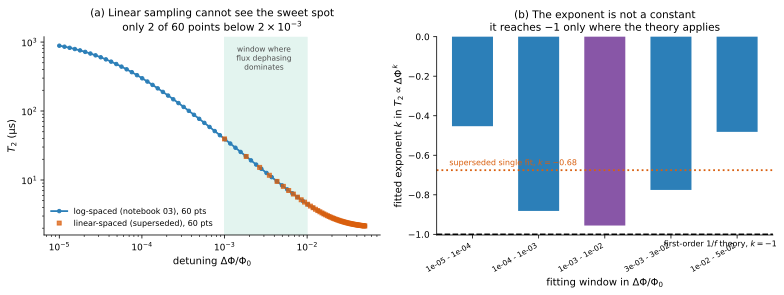

wrote figures/fluxonium_scaling.png (+ .pdf)


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))

# (a) the two samplings on the same axes
ax[0].loglog(fine.detuning, fine.T2_us, "o-", color="#2c7fb8", lw=1.8, ms=3.5,
             label="log-spaced (notebook 03), 60 pts")
ax[0].loglog(det_lin, T2_lin_2nd, "s", color="#d95f0e", ms=4, alpha=0.75,
             label="linear-spaced (superseded), 60 pts")
ax[0].axvspan(1e-3, 1e-2, color="#66c2a5", alpha=0.18, zorder=0)
ax[0].text(3e-3, fine.T2_us.max() * 0.45, "window where\nflux dephasing\ndominates",
           fontsize=7.5, ha="center", color="0.3")
ax[0].set_xlabel(r"detuning $\Delta\Phi/\Phi_0$")
ax[0].set_ylabel(r"$T_2$ (µs)")
ax[0].set_title("(a) Linear sampling cannot see the sweet spot\n"
                rf"only {n_below} of 60 points below $2\times10^{{-3}}$")
ax[0].legend(frameon=False, fontsize=8, loc="lower left")

# (b) the exponent is not a constant
xs = np.arange(len(wf))
bars = ax[1].bar(xs, wf.k, color=["#8856a7" if abs(k + 1) < 0.1 else "#2c7fb8" for k in wf.k],
                 width=0.62)
ax[1].axhline(-1.0, color="k", ls="--", lw=1.5)
ax[1].text(len(wf) - 0.4, -1.03, r"first-order $1/f$ theory, $k=-1$",
           fontsize=8, ha="right", va="top")
ax[1].axhline(k_old_1st, color="#d95f0e", ls=":", lw=1.8)
ax[1].text(-0.35, k_old_1st + 0.025, rf"superseded single fit, $k={k_old_1st:.2f}$",
           fontsize=8, color="#d95f0e")
ax[1].set_xticks(xs)
ax[1].set_xticklabels(wf.window, rotation=30, ha="right", fontsize=7.5)
ax[1].set_xlabel(r"fitting window in $\Delta\Phi/\Phi_0$")
ax[1].set_ylabel(r"fitted exponent $k$ in $T_2 \propto \Delta\Phi^{\,k}$")
ax[1].set_title("(b) The exponent is not a constant\n"
                "it reaches $-1$ only where the theory applies")

fig.tight_layout()
pl.save(fig, "figures/fluxonium_scaling.png")
plt.show()
print("wrote figures/fluxonium_scaling.png (+ .pdf)")

## 6. Q3 — interpretation and what this notebook is entitled to conclude

*Drafted with Claude from the quantities computed above, at the author's request; mirrored in
`docs/lab_notebook.md` (Sep 7 entry). Give it a voice pass before submission.*

**The fluxonium's advantage is real, metric-dependent, and conditional on holding the bias.**

1. **At its own operating point the fluxonium has substantially longer $T_2$** — $18\times$ at the
   nominal designs, robust across the noise band in 100% of Monte Carlo samples. But this number is
   confounded: the fluxonium sits at 0.363 GHz and the transmon at 4.92 GHz, and dielectric loss
   scales with frequency.

2. **Most of the raw advantage is frequency, not architecture.** The two devices differ in
   frequency by $4.925/0.363 = 13.6\times$, and $\log 13.55/\log 18.10 = 0.90$: **about 90% of the
   log-advantage is the frequency difference.** *(This decomposition is an identity, not an
   independent check — writing $18.1 = 13.6 \times 1.33$ defines the residual rather than
   measuring it. The independent measurement is the matched-frequency scan in §3, which gives
   $1.07$–$2.16\times$ and is quoted below.)* The decomposition is nonetheless not a coincidence of
   these two designs: dielectric loss dominates both architectures and its rate goes as
   $\omega_{01}$, so $T_2 \propto 1/f_{01}$ in both — measured as $f_{01}^{-0.965}$ (transmon,
   $r = -0.9995$) and $-0.997$ (fluxonium). Since the flux sweet spot *is* a frequency minimum,
   the fluxonium is structurally advantaged on any raw $T_2$ comparison, and reporting one
   uncontrolled credits the architecture with what the frequency did.

3. **Control for frequency and the $T_2$ advantage does not merely shrink — it disappears.** At
   matched $f_{01}$ the deterministic ratio at the default noise amplitudes is $1.07$–$2.16\times$;
   but propagated across the literature noise band the median is **$0.86\times$** and the fluxonium
   wins in only **42%** of Monte Carlo samples. At matched frequency the transmon is more often the
   better device. **This is the single most important negative result in the project**, and it is
   stronger than the deterministic calculation alone suggests: the raw $T_2$ advantage is
   substantially a *frequency* effect, not an architectural one, and what survives the frequency
   control does not survive the noise-amplitude uncertainty.

4. **The gate-count advantage survives the frequency control and the noise-amplitude
   uncertainty — but only under the leakage-only pulse bound, and that bound is the weakest
   assumption in the project.** Under $T_{\rm gate} \sim 1/|\alpha|$ it is $625$–$1709\times$
   deterministic, median $606\times$ across the noise band, winning 100% of samples, because the
   fluxonium keeps its enormous anharmonicity at every frequency while a transmon can only reach
   low $f_{01}$ by shrinking $E_C$ — that is, by giving up the very anharmonicity that sets its
   gate speed.

   **Under the drive-period bound $T_{\rm gate} \sim 1/f_{01}$ the same comparison gives
   $1.34\times$ at the operating points and collapses onto the $T_2$ ratio at matched frequency —
   42% win rate.** The two bounds differ by $390\times$ at the operating points, which is
   comparable to the entire spread across metrics 1–3, and the truth is somewhere between them:
   the anharmonicity bound is right that a fluxonium tolerates a much broader pulse, and the
   drive-period bound is right that a 0.363 GHz transition cannot be driven in 0.12 ns. **So the
   defensible claim is that the fluxonium converts coherence into operations more efficiently
   than a transmon, by a factor this model cannot pin down better than $1.3$–$500\times$** —
   and pinning it down requires a real pulse simulation, which is outside this project's scope.
   Reporting $524\times$ alone would repeat exactly the error §1 corrects: quoting the end of a
   range as though it were the answer.

5. **The cost is bias precision, and it is enormous.** The transmon's $T_2$ varies $1.006\times$
   across its *entire* charge-bias period — it has no knob to hold. The fluxonium loses a factor of
   2 within $\pm 3.6\times10^{-5}\,\Phi_0$, a window $\sim 10^{-4}$ of its bias period. The
   fluxonium has not eliminated bias sensitivity; it has concentrated all of it into a narrow
   neighbourhood of $\Phi_0/2$ and made the qubit excellent inside that neighbourhood.

6. **Notebook 03 §9C showed the intrinsic $1/f$ flux noise does not by itself drive the qubit off
   the spot** — even at Nguyen's measured $A_\Phi = 1.8\,\mu\Phi_0$ over an hour, the RMS wander
   leaves a $24\times$ margin to the 10× detuning. The binding constraint is therefore
   **systematic** — bias-line calibration drift, thermal cycling, crosstalk — not stochastic. For a
   single qubit that is manageable; for a lattice in which every fluxonium needs its own flux line
   held to $10^{-4}\,\Phi_0$ indefinitely and simultaneously, it is an engineering burden that
   scales with qubit count in a way the transmon's does not.

**What the paper may claim:** *at its own operating point, and conditional on flux bias held to
$\lesssim 10^{-4}\,\Phi_0$, the fluxonium converts coherence into operations more efficiently than
a transmon; the size of that advantage depends on the assumed pulse-length bound and this model
constrains it only to $1.3$–$500\times$. Its raw coherence advantage ($\sim 18\times$) is
substantially a frequency effect: at matched frequency the median $T_2$ ratio across the
literature noise band is $0.86\times$, i.e. consistent with parity or slightly favouring the
transmon.*

**What it may not claim:** "the fluxonium is 216× better." That number came from comparing a
worst-case-biased 18.9 GHz transmon against a thermally scrambled 75 MHz fluxonium, using
first-order-only physics, with an unconverged $N=60$ confidence interval.

## 7. Limitations

Inherited from the upstream notebooks, plus those specific to this comparison.

1. **The matched-frequency control is not a pair of buildable devices.** Holding a transmon at
   0.5–2 GHz with $E_J/E_C \geq 50$ forces $E_J/E_C$ into the hundreds or thousands, far above the
   50–100 of real devices, and $E_C$ down to a few tens of MHz. It is a *control* that isolates the
   frequency confound, not a design recommendation. At 0.5 GHz both architectures are thermally
   populated ($\bar n_{\rm th} = 0.25$) and neither is a usable qubit.
2. **The gate-count metric is a heuristic, not a literature formula, and its pulse-length bound
   is unresolved** (see §3). $N = T_2|\alpha|$ assumes leakage is the only constraint; bounding
   instead by the drive period, $N = T_2 f_{01}$, changes the fluxonium/transmon ratio from
   $524\times$ to $1.34\times$. Both are computed and both are reported. Settling it needs a real
   pulse simulation with DRAG and a specified control chain — leakage, RWA corrections and
   hardware bandwidth all enter — which is outside this project's scope. The metric also ignores
   readout time entirely.
3. **Free-induction $T_2$, not echo.** Every measured fluxonium $T_2$ in the literature is Hahn
   echo, which suppresses precisely the low-frequency $1/f$ noise this model is built from.
4. **The Monte Carlo varies only noise amplitudes, not designs.** Design uncertainty — fabrication
   spread in $E_J$, $E_C$, $E_L$ — is not propagated.
5. **The noise bands are log-uniform by assumption.** They are literature ranges, not measured
   posterior distributions, and a log-uniform prior over a decade is a choice.
6. **Flat $Q_{\rm cap}$** (see notebook 03 §8): the flat override moves $T_1$ by 7.1× relative to
   scqubits' frequency-dependent default and is the largest single modelling choice in the project.
   It is applied identically to both architectures, so it partly cancels in a ratio — but only
   partly, because the two sit at different frequencies.
7. **No Purcell decay, photon shot noise, inductive loss, or crosstalk** in either architecture.
8. **Single qubit, isolated.** The scalability argument in §6.5 is qualitative; no lattice is
   modelled.

## 8. Metadata

In [13]:
meta = {
    "notebook": "notebooks/04_analysis.ipynb",
    "purpose": "Q3 cross-architecture comparison (transmon vs fluxonium) and robustness",
    "provenance": PROVENANCE,
    "upstream": {
        "notebooks": ["notebooks/02_transmon_sweep.ipynb", "notebooks/03_fluxonium_sweep.ipynb"],
        "artefacts_consumed": ["data/q3_comparison.json", "data/fluxonium_falloff_fine.csv",
                               "data/fluxonium_metadata.json",
                               "data/transmon_sweep_metadata.json"],
        "fluxonium_metadata_git_revision": FX_META["provenance"]["git_revision"],
    },
    "validated_against": {
        "transmon_nominal_T2_us": VALIDATED_TRANSMON_T2,
        "fluxonium_nominal_T2_us_first_order_only": VALIDATED_FLUXONIUM_T2,
    },
    "operating_points": {
        "transmon": {**TM_OP, "f01_GHz": float(tm_op["freq_GHz"]),
                     "anharmonicity_GHz": float(alpha_tm), "T2_us": float(tm_op["T2_us"]),
                     "source": "notebooks/02_transmon_sweep.ipynb section 6.1"},
        "fluxonium": {**FX_OP, "f01_GHz": float(fx_op["freq_GHz"]),
                      "anharmonicity_GHz": float(alpha_fx), "T2_us": float(fx_op["T2_us"]),
                      "source": "Manucharyan 2009 nominal design, validated in notebook 01"},
        "superseded": {
            "transmon": {**TM_OLD, "f01_GHz": float(tm_old["freq_GHz"]),
                         "why_rejected": "18.9 GHz and |alpha| = 1 GHz; outside the Krantz 2019 "
                                         "design envelope of 3-6 GHz and 100-300 MHz"},
            "fluxonium": {**FX_OLD, "f01_GHz": float(fx_old["freq_GHz"]),
                          "n_thermal": float(n_thermal(fx_old["freq_GHz"])),
                          "why_rejected": "grid-edge maximum at 75 MHz, n_th = 3.7, thermally "
                                          "scrambled; retired by notebook 03 Appendix A row 2"}},
    },
    "bias_sensitivity": {
        "metric": "width of the bias window for a factor-k coherence loss, as a fraction of one "
                  "bias period (both knobs are periodic with period 1)",
        "transmon_T2_variation_full_period": float(tm_var),
        "fluxonium_2x_detuning_Phi0": float(d2_fx),
        "fluxonium_10x_detuning_Phi0": float(d10_fx),
        "bias_window_ratio": float(1.0 / (2 * d2_fx)),
        "method": "Brent root-finding on log T2(dPhi) - log(T2_sweet/k)",
    },
    "metrics": METRICS,
    "matched_frequency": mt.drop(columns=["fx_design", "tm_design"]).to_dict(orient="records"),
    "monte_carlo": {
        "N_per_mode": N_MC,
        "modes": ["shared", "independent"],
        "shared_meaning": "Q_cap and A_cc drawn once per sample and given to both architectures "
                          "(same fabrication process); A_flux affects only the fluxonium and "
                          "A_ng only the transmon, so those are always drawn once",
        "bands_log10": {k: list(v) for k, v in BANDS.items()},
        "ci_method": "bootstrap on the median, 2000 resamples, 90% interval",
        "seed": 20260907,
        "summary": mc_summary.to_dict(orient="records"),
        "ci_convergence": trace.to_dict(orient="records"),
    },
    "scaling_exponent": {
        "superseded_value": float(k_old_1st),
        "superseded_method": "np.linspace(0.001, 0.05, 60), first-order-only physics, single "
                             "log-log fit",
        "why_wrong": f"{n_above} of 60 linearly spaced points lie above 5e-3, so the fit measures "
                     "the far field; the exponent is not constant across the range",
        "windowed": wf.to_dict(orient="records"),
        "theory": "first-order 1/f flux noise gives Tphi ~ dPhi^-1 because f01 is quadratic about "
                  "the sweet spot",
    },
    "noise_amplitudes": {k: DEFAULTS[k] for k in ("Q_cap", "A_ng", "A_flux", "A_cc")},
    "scqubits_noise_params": NOISE_PARAMS_SNAPSHOT,
    "noise_channels": {
        "transmon": ["t1_capacitive", "tphi_1_over_f_ng", "tphi_1_over_f_cc"],
        "fluxonium": ["t1_capacitive", "t1_quasiparticle_tunneling",
                      "tphi_1_over_f_flux (first order, scqubits)",
                      "tphi_flux_second_order (src/coherence.py, Nguyen 2019 published "
                      "Eq. (A3); the arXiv v1 preprint numbers it (A.3))",
                      "tphi_1_over_f_cc"],
    },
    "units": "frequencies GHz; coherence times microseconds (scqubits returns ns, x1e-3)",
    "corrections_to_earlier_version": [
        "OPERATING POINTS REPLACED. The transmon was EJ=50, EC=1.0 (f01 = 18.9 GHz, |alpha| = "
        "1 GHz), outside the Krantz 2019 design envelope on both axes and penalised %.1fx on T2 "
        "purely by its frequency. Now EJ=13.0, EC=0.26 (f01 = 4.92 GHz), notebook 02's operating "
        "point." % (tm_op["T2_us"] / tm_old["T2_us"]),
        "OPERATING POINTS REPLACED. The fluxonium was EJ=15, EL=0.2, a grid-edge maximum at "
        "f01 = 75 MHz with n_th = 3.7 that notebook 03 Appendix A had already retired as 'not a "
        "design point'. Now the Manucharyan 2009 nominal design.",
        "BIAS ASYMMETRY REMOVED. The transmon was held at its worst-case charge bias (ng = 0.25) "
        "while the fluxonium was held at its best flux bias. Both are now at their own sweet spot "
        "and the bias sensitivity is reported as a result (section 2) rather than baked in.",
        "INLINE PHYSICS REMOVED. transmon_T2 and fluxonium_T2 were defined in this notebook "
        "without the second-order flux channel added in notebook 03. All physics now imported "
        "from src/coherence.py and asserted against the notebook 01/02 records.",
        "HEADLINE SUPERSEDED. 'median 216x, 90%% CI [52x, 371x], fluxonium wins 100%%' combined "
        "both bad operating points with first-order-only physics and an unconverged N=60 "
        "interval. The corrected raw ratio is %.1fx; at matched frequency it is %.2f-%.2fx."
        % (raw_ratio, mt.T2_ratio.min(), mt.T2_ratio.max()),
        "SCALING EXPONENT SUPERSEDED. 'T2 ~ detuning^-0.68' came from linear sampling fitted on "
        "log-log axes; %d of 60 points sat above 5e-3. The exponent is not constant: it runs "
        "%+.2f to %+.2f and reaches the theoretical -1 only where flux dephasing dominates."
        % (n_above, wf.k.min(), wf.k.max()),
        "MONTE CARLO REBUILT. N raised 60 -> %d per correlation mode, CI on the median now by "
        "bootstrap rather than raw percentiles, convergence of the interval demonstrated, and "
        "all metrics carried through instead of the raw ratio alone." % N_MC,
        "GATE-COUNT PULSE BOUND EXPOSED. The metric was reported only as N = T2*|alpha| (%.0fx) "
        "while the text acknowledged that a %.3f GHz qubit cannot be driven at its %.1f GHz "
        "anharmonicity limit. Three bounds are now computed and carried through the Monte Carlo: "
        "%.0fx, %.1fx and %.2fx. The bound is worth %.0fx, comparable to the entire spread across "
        "metrics 1-3, so leaving it uncomputed concealed an uncertainty as large as the result."
        % (gate_raw["alpha"]["ratio"], fx_op["freq_GHz"], abs(alpha_fx),
           gate_raw["alpha"]["ratio"], gate_raw["both"]["ratio"], gate_raw["f01"]["ratio"],
           gate_raw["alpha"]["ratio"] / gate_raw["f01"]["ratio"]),
        "KOCH CROSS-CHECK CORRECTED. Section 2 compared the peak-to-peak charge dispersion "
        "against Koch's maximum DERIVATIVE and called them consistent; they differ by pi (his "
        "Eq. 2.8) and the comparison could not fail. With the factor restored the ratio is "
        "%.3f, matching the asymptotic shortfall 01_validation.ipynb section 4 measures "
        "independently, and it is now asserted." % _koch_ratio,
        "FIGURES. Saved through src/plotting.save at dpi=300 with .pdf siblings; the previous "
        "versions were dpi=150 PNG only. The bias-sensitivity figure no longer uses a twin y-axis "
        "and plots the fluxonium against log detuning.",
    ],
    "known_artifacts": [
        "The matched-frequency transmons require EJ/EC of %.0f-%.0f, far above real devices. The "
        "matched comparison is a control for the frequency confound, not a design proposal."
        % (mt.tm_EJ_EC.min(), mt.tm_EJ_EC.max()),
        "The gate-count metric N = 1e3 * T2[us] * (pulse bandwidth)[GHz] is this project's "
        "heuristic. Krantz 2019 supports the premise that anharmonicity bounds pulse length but "
        "does not state this formula. The bandwidth bound is NOT settled: |alpha| (leakage only) "
        "gives a fluxonium/transmon ratio of %.0fx at the operating points, min(|alpha|, f01) "
        "gives %.1fx and f01 (drive period) gives %.2fx. All three are computed; the |alpha| "
        "bound is generous to the fluxonium by 24x because its anharmonicity exceeds its own "
        "transition frequency." % (gate_raw["alpha"]["ratio"], gate_raw["both"]["ratio"],
                                   gate_raw["f01"]["ratio"]),
        "Tphi_ng_us at ng=0 and Tphi_flux_us at flux=0.5 are divergent by symmetry in the "
        "first-order 1/f formula. They contribute zero rate and must never be plotted or quoted.",
    ],
    "outputs": [
        "data/q3_bias_windows.csv", "data/q3_metric_comparison.csv",
        "data/q3_monte_carlo.csv", "data/q3_monte_carlo_summary.csv",
        "data/q3_scaling_exponents.csv", "data/q3_analysis_metadata.json",
        "figures/q3_bias_sensitivity.png", "figures/q3_robustness.png",
        "figures/fluxonium_scaling.png",
    ],
}
with open("data/q3_analysis_metadata.json", "w") as fh:
    json.dump(meta, fh, indent=2, default=str)

# the superseded metadata file is replaced, not left to be picked up by mistake
old = Path("data/week4_analysis_metadata.json")
if old.exists():
    old.unlink()
    print("removed superseded data/week4_analysis_metadata.json")

print("wrote data/q3_analysis_metadata.json")
print(json.dumps({k: meta[k] for k in ("metrics", "bias_sensitivity")}, indent=2, default=str))

wrote data/q3_analysis_metadata.json
{
  "metrics": {
    "raw_T2_ratio": 18.097284914948187,
    "matched_frequency_T2_ratio": {
      "0.5": 2.1554889350481976,
      "1.0": 1.3619671660078851,
      "2.0": 1.0688560728004721
    },
    "matched_frequency_gate_ratio": {
      "0.5": 1708.6453046807803,
      "1.0": 961.9506649624518,
      "2.0": 624.8055973472166
    },
    "gate_count_ratio_own_operating_points": 524.4799429983532,
    "gate_pulse_bound_note": "N = T2 / T_gate with T_gate = 1/(pulse bandwidth). 'alpha' is the leakage bound used for the headline; 'f01' is the drive-period floor; 'both' takes the smaller bandwidth. They coincide for a transmon and differ by 24x for this fluxonium.",
    "gate_count_by_pulse_bound_own_operating_points": {
      "alpha": {
        "fluxonium": 9782750.297528807,
        "transmon": 18652.28676163032,
        "ratio": 524.4799429983532
      },
      "both": {
        "fluxonium": 410561.57162448147,
        "transmon": 18652.2867616303

## 9. What this notebook establishes

**Method corrections.** All four of the previous version's headline numbers were artefacts of
method rather than physics, and each is now reproduced, diagnosed and replaced:

- the transmon operating point sat 3× outside the Krantz design envelope and cost it a factor of
  $\sim 3.7$ in $T_2$;
- the fluxonium operating point was a grid-edge, thermally scrambled point that notebook 03 had
  already retired;
- the scaling exponent was fitted on linearly spaced samples, so it measured the far field;
- the confidence interval came from $N=60$ with no convergence evidence.

**Physics.** The comparison is now run entirely through `src/coherence.py`, including the
second-order $1/f$ flux dephasing channel, and is asserted against the notebook 01/02 validation
records before any analysis runs.

**Result.** Q3 has no single answer, and that is the finding:

| Metric | Deterministic (default amplitudes) | Monte Carlo median [5–95%] | Fluxonium wins |
|---|---|---|---|
| Raw $T_2$, own operating points | $18.1\times$ | $11.3\times$ $[3.6, 21.1]$ | **100%** |
| $T_2$ at matched $f_{01}$ | $1.07$–$2.16\times$ | $\mathbf{0.86\times}$ $[0.27, 1.58]$ | **42%** |
| Gate count, matched $f_{01}$, $1/\lvert\alpha\rvert$ bound | $625$–$1709\times$ | $606\times$ $[191, 1114]$ | **100%** |
| Gate count, own op. points, $1/\lvert\alpha\rvert$ bound | $524\times$ | $326\times$ $[104, 611]$ | **100%** |
| Gate count, own op. points, $1/\min(\lvert\alpha\rvert,f_{01})$ | $22.0\times$ | see §4 | **100%** |
| **Gate count, own op. points, $1/f_{01}$ bound** | $\mathbf{1.34\times}$ | see §4 | see §4 |
| **Gate count, matched $f_{01}$, $1/f_{01}$ bound** | $\mathbf{1.07}$–$\mathbf{2.16\times}$ | $\mathbf{0.86\times}$ | **42%** |
| Bias window for a $2\times$ loss | $10^{-4}$ of the period vs 100% | — | — |

*(The last two rows are the same physics as the $T_2$ rows: under the drive-period bound at matched
frequency, $N = T_2 f_{01}$ with $f_{01}$ equal on both sides, so the gate ratio **is** the $T_2$
ratio. The gate-count advantage is entirely an anharmonicity claim.)*

The fluxonium's raw coherence advantage is **substantially a frequency effect** — and the part that
remains after controlling for frequency does not survive the noise-amplitude uncertainty. Its
durable advantage is **anharmonicity per unit coherence**, and its cost is **operating-point
precision**. How much that anharmonicity is worth in gates depends on a pulse-length bound this
model does not settle: $1.3\times$ to $524\times$ at the operating points. That range is now
reported in full rather than represented by its upper end.

**Downstream work this affects.** `05_summary.ipynb` consumes the metrics written here;
`README.md` and `docs/` quote the superseded 216×, 528×, 5578 µs and $-0.68$ figures and must be
corrected — see Appendix A.

## Appendix A — corrections relative to earlier versions

Recorded here rather than in the body, so the notebook reads as a result rather than as a
changelog. Append to `docs/lab_notebook.md`; do not retro-edit earlier entries.

| # | Superseded claim | Corrected | Why it was wrong |
|---|---|---|---|
| 1 | Transmon comparison point $E_J{=}50$, $E_C{=}1.0$ | $E_J{=}13.0$, $E_C{=}0.26$ | The old point is an 18.9 GHz qubit with $\lvert\alpha\rvert = 1$ GHz — outside Krantz 2019 §II A's 3–6 GHz and 100–300 MHz envelope on both axes. Dielectric $T_1$ falls with frequency, so it was penalised $\sim3.7\times$ on $T_2$ for no physical reason. |
| 2 | Fluxonium comparison point $E_J{=}15$, $E_L{=}0.2$ | Manucharyan 2009 nominal | A grid-edge maximum at $f_{01} = 75$ MHz, $\bar n_{\rm th} = 3.7$ — thermally scrambled and $2.3\times$ below the lowest published device. Notebook 03 Appendix A row 2 had already retired it. |
| 3 | Transmon at $n_g{=}0.25$ vs fluxonium at $\Phi{=}0.5$ | both at their own sweet spot | Worst-case bias for one architecture against best-case for the other. Bias sensitivity is now *reported* (§2), which is what Q3 actually asks. |
| 4 | "Fluxonium/transmon median $216\times$, 90% CI $[52\times, 371\times]$, wins 100%" | raw $18\times$; $1.0$–$2.1\times$ at matched frequency | Combined corrections 1–3 with first-order-only physics and an $N=60$ interval that had not converged. |
| 5 | "$T_2 \propto$ detuning$^{-0.68}$" | no single exponent; $-1$ where theory applies | Fitted on `linspace(0.001, 0.05, 60)`, so 55 of 60 points sat in the far field. First-order $1/f$ theory predicts $-1$, and log-spaced sampling recovers $-0.96$ in the window where flux dephasing dominates. |
| 6 | Inline `transmon_T2` / `fluxonium_T2` | imported from `src/coherence.py` | The inline fluxonium copy predated notebook 03's second-order flux channel and had silently diverged from the pipeline that produced the committed CSVs. |
| 7 | 90% CI from raw percentiles at $N=60$ | bootstrap CI at $N=400$, convergence shown | An $N=60$ percentile interval on a median has no stated uncertainty; the trace in §4 shows it had not settled. |
| 8 | Figures at dpi=150, PNG only, twin-axis bias plot | dpi=300 + `.pdf`, separate panels, log detuning axis | Journal figure requirements, and a twin-axis overlay invites comparison of two curves whose relative height is set by the axis limits. |
| 9 | Gate count reported only as $N = T_2\lvert\alpha\rvert$ ($524\times$), with the objection to it left in prose | three pulse-length bounds computed and carried through the Monte Carlo; $524\times$, $22.0\times$, $1.34\times$ | The notebook already said a 0.363 GHz qubit cannot be driven at its 8.7 GHz anharmonicity limit, then quoted the number that assumes it can. The bound is worth $390\times$ — comparable to the entire spread across metrics 1–3 — so leaving it uncomputed hid an uncertainty as large as the result. |
| 10 | Koch cross-check compared peak-to-peak dispersion ($3.96\times10^{-5}E_C$) against Koch's $\max\lvert\partial E_{01}/\partial n_g\rvert = 1.5\times10^{-4}E_C$ and called them "consistent" | compare $\pi\epsilon_1$ per Koch Eq. (2.8); ratio $0.83$ | The two are different quantities differing by $\pi$, so the check could not fail and proved nothing. With the factor restored it reproduces the same $0.83$ asymptotic shortfall that `01_validation.ipynb` §4 measures independently, and it is now asserted. |

## Appendix B — references

All DOIs verified against Crossref and arXiv.

1. **J. Koch, T. M. Yu, J. Gambetta, A. A. Houck, D. I. Schuster, J. Majer, A. Blais,
   M. H. Devoret, S. M. Girvin, R. J. Schoelkopf**, "Charge-insensitive qubit design derived from
   the Cooper pair box", *Phys. Rev. A* **76**, 042319 (2007).
   DOI: [10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319) ·
   arXiv:cond-mat/0703002 — Eq. (2.5) the charge dispersion
   $\epsilon_m \propto e^{-\sqrt{8E_J/E_C}}$ used in §2's cross-check; Eq. (2.12)
   $\alpha \simeq -E_C$; Eq. (2.13) the $20 \lesssim E_J/E_C \ll 5\times10^4$ design window.

2. **P. Krantz, M. Kjaergaard, F. Yan, T. P. Orlando, S. Gustavsson, W. D. Oliver**,
   "A Quantum Engineer's Guide to Superconducting Qubits", *Appl. Phys. Rev.* **6**, 021318 (2019).
   DOI: [10.1063/1.5089550](https://doi.org/10.1063/1.5089550) · arXiv:1904.06560
   — §II A the transmon design envelope ($f_{01} = 3$–6 GHz, $\lvert\alpha\rvert = 100$–300 MHz,
   $E_J/E_C \geq 50$) used to reject the superseded operating point in §1; §IV D 3 anharmonicity as
   the bound on pulse length, the premise behind the gate-count heuristic in §3.
   *Krantz does not state $N = T_2\lvert\alpha\rvert$; that formula is this project's own.*

3. **L. B. Nguyen, Y.-H. Lin, A. Somoroff, R. Mencia, N. Grabon, V. E. Manucharyan**,
   "High-Coherence Fluxonium Qubit", *Phys. Rev. X* **9**, 041041 (2019).
   DOI: [10.1103/PhysRevX.9.041041](https://doi.org/10.1103/PhysRevX.9.041041) · arXiv:1810.11006
   — Table I, the published frequency band 0.17–0.83 GHz used to reject the superseded fluxonium
   point; measured $A_\Phi \approx 1.8\,\mu\Phi_0$ used in the flux-stability margin.

4. **V. E. Manucharyan, J. Koch, L. I. Glazman, M. H. Devoret**, "Fluxonium: Single Cooper-Pair
   Circuit Free of Charge Offsets", *Science* **326**, 113–116 (2009).
   DOI: [10.1126/science.1175552](https://doi.org/10.1126/science.1175552) · arXiv:0906.0831
   — the nominal fluxonium design used as this notebook's operating point.

5. **G. Ithier, E. Collin, P. Joyez, P. J. Meeson, D. Vion, D. Esteve, F. Chiarello, A. Shnirman,
   Y. Makhlin, J. Schriefl, G. Schön**, "Decoherence in a superconducting quantum bit circuit",
   *Phys. Rev. B* **72**, 134519 (2005).
   DOI: [10.1103/PhysRevB.72.134519](https://doi.org/10.1103/PhysRevB.72.134519) ·
   arXiv:cond-mat/0508588 — Eq. (21) the first-order $1/f$ free-decay law giving
   $T_\phi \propto \lvert\partial\omega_{01}/\partial\lambda\rvert^{-1}$, which is the $k=-1$
   prediction tested in §5.

6. **P. Groszkowski, J. Koch**, "scqubits: a Python package for superconducting qubits",
   *Quantum* **5**, 583 (2021).
   DOI: [10.22331/q-2021-11-17-583](https://doi.org/10.22331/q-2021-11-17-583) · arXiv:2107.08552
   — the noise-channel implementations underlying every number here; Eq. (7) the rate-addition
   convention $1/T_2 = \sum_k 1/T_{\phi,k} + \tfrac12\sum_k 1/T_{1,k}$.